# Capstone: Flagging Toxic Comments for Human Moderators

**Author:** Viola Kempa

> **Content warning:** this notebook prints real online comments. Some contain slurs, profanity and threats. They
> appear because the error analysis depends on reading them.

## Executive summary

**Problem.** Busy news sites receive more comments than their moderators can read. This project builds a model that
sorts comments by how likely they are to be toxic, so moderators can read the worst ones first. It uses Civil
Comments: about 2 million English comments from news sites (2015 to 2017), each rated by several crowd workers. A
comment counts as toxic when at least half of its raters said so. That is true for 8% of comments.

**Approach.** The comments were cleaned lightly and explored with spaCy. Toxic comments are not longer than harmless
ones, but they address people more often ("you", "your") and use more exclamation marks. Identity words such as
"black" and "white" are already among the most common adjectives in toxic comments. Two models learned from 50,000
comments and were tested on 97,320 others: a simple word-counting baseline (TF-IDF with logistic regression) and
DistilBERT, a pretrained language model fine-tuned on a laptop GPU.

**Results.**

| Test set | Baseline | DistilBERT |
|---|---|---|
| F1 (balance of precision and recall) | 0.55 | 0.66 |
| PR-AUC (how well toxic comments are ranked first) | 0.59 | 0.73 |
| share of flagged comments that are toxic, when 80% of toxic comments are caught | 0.29 | 0.50 |

DistilBERT is better on every measure, and the gap is far too large to be chance. For moderators this means about
one harmless comment per toxic one in the queue, instead of more than two. Most mistakes happen where the annotators
themselves were split. DistilBERT raises false alarms on harsh words aimed at ideas ("a ridiculous analogy") and
misses insults that contain no rude words. An explainability method (Integrated Gradients) shows that a single word
such as "stupid" often decides the score on its own.

**Risks.** Both models treat some identity words as signs of toxicity. Harmless comments that mention black, white,
Muslim or LGBTQ people are flagged 3 to 4 times as often as harmless comments in general. DistilBERT even gives
harmless sentences like "I am a black person." a score above its flagging threshold. Used to remove comments
automatically, it would silence people for talking about who they are.

**Recommendation.** Use DistilBERT only to sort a moderation queue in a supervised pilot, with a person deciding about
every comment. Never use it to remove comments on its own. Before any wider use, the identity bias has to be reduced
(for example by adding harmless training comments that mention identities) and tested again, ideally on comments
whose identity groups were labelled by people.

## 1. Setup

The exact package versions are pinned in `requirements.txt`, together with the spaCy English model. The install line
below is left commented out on purpose: uncomment it only in a fresh environment.

In [106]:
# %pip install -r requirements.txt

Some libraries print harmless notes while they load: a missing Jupyter widget for progress bars, a macOS logging
note from PyTorch, a reminder to log in to Hugging Face, and progress bars. The next cell hides them, so the outputs
below show only results. It does not change any computation.

In [107]:
import logging
import warnings

# These two filters only work if they are set before the libraries below are imported.
warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").disabled = True

import datasets
import huggingface_hub
import transformers

datasets.disable_progress_bars()
transformers.logging.disable_progress_bar()
transformers.logging.set_verbosity_error()
huggingface_hub.utils.logging.set_verbosity_error()

Imports and every setting the rest of the notebook reads. `TOXIC_THRESHOLD` turns the annotators' score into a label.
`TRAIN_SIZE` and `VALIDATION_SIZE` control how many comments are sampled from the dataset's own splits; the test split
is used in full. The transformer settings follow the usual DistilBERT fine-tuning recipe. `DEVICE` picks the Apple GPU
(`mps`) when there is one.

In [108]:
import html
import json
import platform
import random
import re
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import spacy
import torch
import transformers
from captum.attr import LayerIntegratedGradients
from datasets import Dataset, load_dataset
from IPython.display import HTML, display
from scipy.optimize import minimize_scalar
from sklearn.calibration import calibration_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score, f1_score, log_loss,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, PrinterCallback,
                          Trainer, TrainingArguments)

plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.max_colwidth", 200)

FIGURES_DIR = Path("figures")
MODEL_DIR = Path("models") / "distilbert_toxicity"
CHECKPOINTS_DIR = Path("models") / "checkpoints"
TRAINING_LOG_PATH = Path("training_log.json")
PREDICTIONS_PATH = Path("test_predictions.parquet")
RESULTS_PATH = Path("results.json")
FIGURES_DIR.mkdir(exist_ok=True)

SEED = 42
DATASET_NAME = "google/civil_comments"
TOXIC_THRESHOLD = 0.5       # share of annotators who rated the comment toxic or very toxic
AMBIGUOUS_BAND = (0.3, 0.7)
TRAIN_SIZE = 50_000
VALIDATION_SIZE = 10_000
EDA_SAMPLE_PER_CLASS = 3_000
CLASS_NAMES = {0: "non-toxic", 1: "toxic"}

TFIDF_C_GRID = [1, 4, 16, 64]

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
BATCH_SIZE = 32
EPOCHS = 2
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
EVAL_EVERY_STEPS = 500
LOG_EVERY_STEPS = 50

DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"

In [109]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


set_seed(SEED)

CONFIG = {
    "seed": SEED, "dataset": DATASET_NAME, "toxic label threshold": TOXIC_THRESHOLD,
    "train comments (sampled)": TRAIN_SIZE, "validation comments (sampled)": VALIDATION_SIZE,
    "test comments": "full test split", "TF-IDF C grid": TFIDF_C_GRID, "transformer": MODEL_NAME,
    "max tokens": MAX_LENGTH, "learning rate": LEARNING_RATE, "batch size": BATCH_SIZE, "epochs": EPOCHS,
    "weight decay": WEIGHT_DECAY, "warmup share of steps": WARMUP_RATIO, "device": DEVICE,
}
VERSIONS = {
    "python": platform.python_version(), "datasets": datasets.__version__, "scikit-learn": sklearn.__version__,
    "spacy": spacy.__version__, "torch": torch.__version__, "transformers": transformers.__version__,
}
results = {"config": CONFIG, "versions": VERSIONS}
display(pd.Series(CONFIG | VERSIONS, dtype=str).to_frame("value"))

,value
seed,42
dataset,google/civil_comments
toxic label threshold,0.5
train comments (sampled),50000
validation comments (sampled),10000
test comments,full test split
TF-IDF C grid,"[1, 4, 16, 64]"
transformer,distilbert-base-uncased
max tokens,128
learning rate,2e-05


**What this shows:** every setting that affects the results, in one place, plus the package versions. With the same
seed and versions, a new run draws the same comments and trains the same baseline. Training on a GPU is not exactly
repeatable, so a retrained DistilBERT can differ slightly, usually in the third decimal.

## 2. Problem framing

- **Dataset:** Civil Comments. It holds about 2 million English comments from around 50
  independent news sites that used the Civil Comments plugin between 2015 and 2017. When the platform shut down, Jigsaw
  (Google) released the comments with crowd-sourced toxicity ratings. Licence CC0, loaded from Hugging Face as
  `google/civil_comments`.
- **Target:** `label = 1` (toxic) when at least half of the annotators rated the comment toxic or very toxic
  (`toxicity >= 0.5`). This is the convention of the Jigsaw competitions built on the same data.
- **Input:** the comment text only. The release has no author, article or date fields.
- **Use case:** a busy comment section receives more comments than its moderators can read. The model sorts the
  moderation queue so that likely toxic comments are read first. A moderator still makes every decision.
- **Stakeholders:** moderators decide which comments to read first, and the site decides the score at which a comment
  jumps the queue. Commenters are affected by both decisions without having a say in either.
- **Out of scope:** removing comments or banning users automatically, other languages, other kinds of platform (social
  media, chat, games) and comments written after 2017.

**Why this dataset.** The text is real and unedited: typos, sarcasm, quotes, shouting and links. The toxic class is
rare (8%), so plain accuracy says almost nothing and the metrics have to be chosen with care. And the dataset was
released because toxicity models were known to treat identity words as signs of toxicity.
That makes the fairness questions in section 10 concrete.

### Hypotheses

- **H1 (model):** fine-tuned DistilBERT reaches a higher test PR-AUC than TF-IDF with logistic regression. Reason: a
  pretrained transformer reads words in context, so it can tell "you are an idiot" from "I felt like an idiot when I
  locked myself out", while TF-IDF only counts words and word pairs.
- **H2 (bias):** both models flag harmless comments that mention an identity group more often than harmless comments
  in general. Reason: identity words show up more often in toxic training comments than in non-toxic ones, and both
  models learn from those co-occurrences.

**Main metric:** PR-AUC for the toxic class (explained below). It measures how well the model puts toxic comments at
the top of the list, which is exactly what a moderation queue needs.

**Success criteria**, fixed before any test result was seen:

1. DistilBERT reaches an F1 of at least 0.60 on the test set and beats TF-IDF + logistic regression by more than
   chance (the bootstrap check in section 7).
2. On every identity slice, the false positive rate is at most twice the overall false positive rate.

### Terms used in this notebook

Both models give each comment a **score** between 0 and 1. A comment is **flagged** when its score is above a chosen
**threshold**.

| Term | Plain meaning |
|---|---|
| precision | of the comments the model flags, the share that really are toxic |
| recall | of the toxic comments, the share the model flags |
| F1 | one number that balances precision and recall; it is only high when both are high |
| PR-AUC | how well the scores rank toxic comments above harmless ones, over every possible threshold. 1 is perfect; a random order scores 0.08 here, the share of toxic comments |
| ROC-AUC | the chance that a random toxic comment gets a higher score than a random harmless one. Looks good too easily when, as here, 92% of comments are harmless |
| false positive rate (FPR) | of the harmless comments, the share that get flagged by mistake |
| false negative rate (FNR) | of the toxic comments, the share that are missed |
| TP, TN, FP, FN | true positive (toxic, flagged), true negative (harmless, not flagged), false positive (harmless, flagged), false negative (toxic, missed) |

## 3. Data

### 3.1 Loading and basic statistics

The Hugging Face release keeps the three splits the dataset authors published. All of them carry the same columns: the
comment `text`, the overall `toxicity` score and six sub-type scores. Each score is the share of crowd annotators who
applied that label, so `toxicity = 0.6` means 6 in 10 annotators called the comment toxic or very toxic.

In [110]:
civil_comments = load_dataset(DATASET_NAME)


def toxic_share(split):
    return float(np.mean(split.data.column("toxicity").to_numpy() >= TOXIC_THRESHOLD))


display(pd.DataFrame({name: {"comments": f"{len(split):,}", "toxic share": f"{toxic_share(split):.1%}"}
                      for name, split in civil_comments.items()}).T)

,comments,toxic share
train,"1,804,874",8.0%
validation,"97,320",7.9%
test,"97,320",8.0%


**What this shows:** all three splits have the same share of toxic comments, 8%, so roughly 1 comment in 12 is
toxic. A model that always answers "non-toxic" would already be right 92% of the time. That is why this notebook
does not judge the models by accuracy.

### 3.2 Split strategy

The dataset's own split is kept, so no test comment is ever used for training or tuning. Training on all 1.8 million
comments would take days on a laptop GPU, so the notebook draws a random sample of 50,000 training and 10,000
validation comments with a fixed seed. The test split is used in full (97,320 comments). The rare identity groups in
section 10 need every test comment they can get.

In [111]:
def sample_comments(split_name, size):
    return civil_comments[split_name].shuffle(seed=SEED).select(range(size)).to_pandas()


train_raw = sample_comments("train", TRAIN_SIZE)
validation_raw = sample_comments("validation", VALIDATION_SIZE)
test_raw = civil_comments["test"].to_pandas()
train_raw.sample(5, random_state=SEED)

,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
33553,",",0.0,0.0,0.0,0.0,0.0,0.0,0.0
9427,"Sure, everything JT does is wrong. Suuuure. Except that lefty National Post comes up with: \nhttp://nationalpost.com/news/politics/emerging-polling-trend-suggests-khadr-settlement-may-not-have-h...",0.0,0.0,0.0,0.0,0.0,0.0,0.0
199,"Reply to Guest_989: The ""host culture"" is still alive and well - within certain pieces of the overall mosaic. I guess you might call them ""enclaves"". It's noticeable if you go to bus terminals i...",0.0,0.0,0.0,0.0,0.0,0.0,0.0
12447,"Isn't point 4 the one titled ""The Big Questions,"" which has a ""4"" in front of it ... the one right below 3 and above 5?",0.0,0.0,0.0,0.0,0.0,0.0,0.0
39489,"You have roughly 5 homicides a week in your home?!\n\nJoking aside, well said.",0.0,0.0,0.0,0.0,0.0,0.0,0.0


**What this shows:** five random training comments, and they are typical of the data. One consists of a single
comma, one is mostly a link to a news article, and several contain line breaks (`\n`). All five have a toxicity
score of 0, like 70% of all comments.

### 3.3 Cleaning

Cleaning is kept light on purpose. Case, punctuation, stopwords and pronouns all carry information about tone, and the
exploratory analysis in section 4 shows that toxic comments use more second-person pronouns. Two things are fixed:

- Links are replaced with the placeholder `URL`. Their exact address says nothing about toxicity and would only add
  one-off tokens to the vocabulary.
- Line breaks and repeated spaces are collapsed into one space.

Scraped web text often contains HTML entities such as `&amp;`, so the table below also counts those. This release has
none (`&` already appears as a plain character), so no decoding step is needed.

In [112]:
HTML_ENTITY_PATTERN = re.compile(r"&[a-zA-Z]+;|&#\d+;")
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+")
WHITESPACE_PATTERN = re.compile(r"\s+")
REPEATED_WHITESPACE_PATTERN = re.compile(r"\n|\s{2,}")


def clean_text(text):
    return WHITESPACE_PATTERN.sub(" ", URL_PATTERN.sub("URL", text)).strip()


def prepare_comments(raw):
    comments = raw.assign(label=(raw["toxicity"] >= TOXIC_THRESHOLD).astype(int),
                          text_clean=raw["text"].map(clean_text))
    return comments[comments["text_clean"] != ""]


CLEANING_RULES = {"HTML entity": HTML_ENTITY_PATTERN, "link": URL_PATTERN,
                  "line break or repeated space": REPEATED_WHITESPACE_PATTERN}
rule_hits = {rule: train_raw["text"].str.contains(pattern) for rule, pattern in CLEANING_RULES.items()}
display(pd.DataFrame({"training comments affected": {rule: f"{hits.sum():,} ({hits.mean():.1%})"
                                                     for rule, hits in rule_hits.items()}}))


def snippet_around_match(text, pattern, width=70):
    match = pattern.search(text)
    return text[max(match.start() - width, 0):match.end() + width]


for rule, hits in rule_hits.items():
    if hits.any():
        snippet = snippet_around_match(train_raw.loc[hits, "text"].iloc[0], CLEANING_RULES[rule])
        print(f"{rule}\n  before: {snippet!r}\n  after:  {clean_text(snippet)!r}\n")

,training comments affected
HTML entity,0 (0.0%)
link,"1,443 (2.9%)"
line break or repeated space,"27,046 (54.1%)"


link
  before: ' capital.\n\nThis is one of many many articles that outline the issue - https://www.cnbc.com/2017/07/19/sexism-and-silicon-valley-why-women-founders-cant-raise-cash.html'
  after:  'capital. This is one of many many articles that outline the issue - URL'

line break or repeated space
  before: 'And I always thought that Eric Trump was the dumbest son.  Sorry, Eric!'
  after:  'And I always thought that Eric Trump was the dumbest son. Sorry, Eric!'



**What this shows:** more than half of the comments contain line breaks or double spaces, and about 3% contain a
link. None contains an HTML entity. In the examples the text stays readable; the long link becomes the single word
`URL` and the layout characters disappear. Whether this cleaning helps the baseline is tested in section 5.

After cleaning, any training or validation comment whose exact text also appears in the test split is removed. Short
stock replies ("Thank you", "Well said") occur many times in the data, and leaving them in both places would let the
models score test comments they have already seen.

In [113]:
train = prepare_comments(train_raw)
validation = prepare_comments(validation_raw)
test = prepare_comments(test_raw)

test_texts = set(test["text_clean"])
train_in_test = train["text_clean"].isin(test_texts)
validation_in_test = validation["text_clean"].isin(test_texts)
print(f"Removed {train_in_test.sum():,} training and {validation_in_test.sum():,} validation comments "
      f"whose text also appears in the test split")
train = train[~train_in_test].reset_index(drop=True)
validation = validation[~validation_in_test].reset_index(drop=True)

SPLITS = {"train": train, "validation": validation, "test": test}
assert not train["text_clean"].isin(test_texts).any() and not validation["text_clean"].isin(test_texts).any()
assert all(0.05 < split["label"].mean() < 0.12 for split in SPLITS.values()), "unexpected share of toxic comments"
display(pd.DataFrame({name: {"comments": f"{len(split):,}", "toxic": f"{split['label'].sum():,}",
                             "toxic share": f"{split['label'].mean():.1%}"} for name, split in SPLITS.items()}).T)

Removed 274 training and 105 validation comments whose text also appears in the test split


,comments,toxic,toxic share
train,"49,726","3,936",7.9%
validation,"9,895",791,8.0%
test,"97,320","7,777",8.0%


**What this shows:** 274 training and 105 validation comments were exact copies of test comments and were removed.
The final splits still hold about 8% toxic comments each: 3,936 toxic comments to learn from, 791 to tune on and
7,777 to test on. The two `assert` lines stop the notebook if a copy slips through or the toxic share looks wrong.

### 3.4 Label certainty

The label is a vote. A comment that 5 of 10 annotators called toxic becomes `toxic`, and one that 4 of 10 called toxic
becomes `non-toxic`, so labels near the 0.5 cut-off are close to a coin flip.

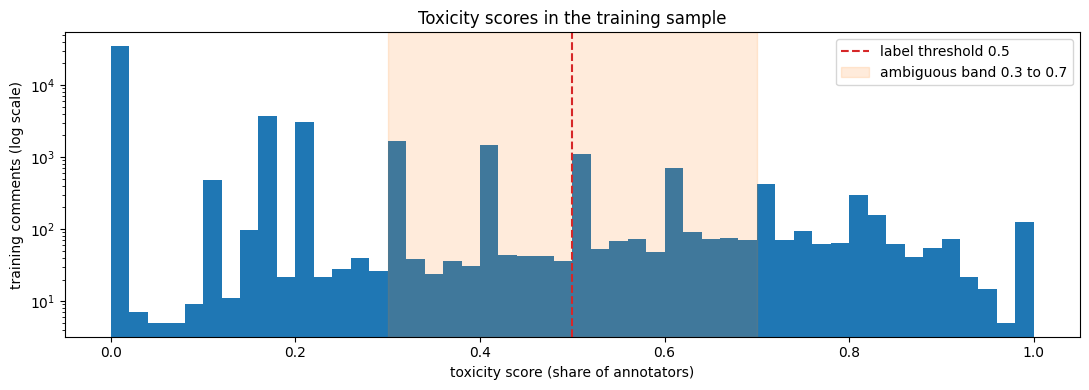

Score exactly 0: 69.8% of training comments
Score in the ambiguous band: 11.8% of all comments, 60.3% of toxic comments


In [114]:
fig, ax = plt.subplots()
ax.hist(train["toxicity"], bins=50, color="tab:blue")
ax.axvline(TOXIC_THRESHOLD, color="tab:red", linestyle="--", label=f"label threshold {TOXIC_THRESHOLD}")
ax.axvspan(*AMBIGUOUS_BAND, color="tab:orange", alpha=0.15, label="ambiguous band 0.3 to 0.7")
ax.set_yscale("log")
ax.set_xlabel("toxicity score (share of annotators)")
ax.set_ylabel("training comments (log scale)")
ax.set_title("Toxicity scores in the training sample")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "toxicity_score_distribution.png", dpi=150)
plt.show()

in_band = train["toxicity"].between(*AMBIGUOUS_BAND, inclusive="left")
print(f"Score exactly 0: {(train['toxicity'] == 0).mean():.1%} of training comments")
print(f"Score in the ambiguous band: {in_band.mean():.1%} of all comments, "
      f"{in_band[train['label'] == 1].mean():.1%} of toxic comments")

**How to read it:** each bar counts comments with a given score. The y-axis is logarithmic, so every step up means
ten times more comments. Everything right of the red line is labelled toxic.

**What this shows:** 70% of comments scored exactly 0; not one annotator found them toxic. The tall spikes (at 0.17,
0.2, 0.4, 0.6 and so on) come from the small number of annotators per comment: with 5 or 6 people, only a few
fractions are possible. The key number for modelling is the second line: 60% of toxic comments score between 0.5 and
0.7, so for most toxic labels a narrow majority decided. Both models will struggle most right around the threshold.

In [115]:
SUBTYPES = ["severe_toxicity", "obscene", "threat", "insult", "identity_attack", "sexual_explicit"]
toxic_train = train[train["label"] == 1]
display(toxic_train[SUBTYPES].ge(TOXIC_THRESHOLD).mean().map("{:.1%}".format)
        .to_frame("share of toxic training comments with this sub-type"))

,share of toxic training comments with this sub-type
severe_toxicity,0.0%
obscene,7.1%
threat,2.4%
insult,71.8%
identity_attack,8.6%
sexual_explicit,2.8%


**What this shows:** annotators also marked what *kind* of toxicity a comment contains. Most toxic comments are
insults (72%). Obscenity, identity attacks, threats and sexual content each make up less than 10%, and no comment was
called severely toxic by a majority. The models will therefore mostly learn what insults look like. They see fewer
than 100 threats among the 50,000 training comments, so they will be weaker on those.

## 4. Exploratory text analysis

spaCy's small English pipeline (`en_core_web_sm`) splits 3,000 toxic and 3,000 non-toxic training comments into
sentences and tokens and tags each token with its part of speech (POS). Equal class sizes make the two groups easy to
compare; they do not reflect the real 8% share of toxic comments.

In [116]:
nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
eda_sample = train.groupby("label").sample(EDA_SAMPLE_PER_CLASS, random_state=SEED).reset_index(drop=True)
eda_docs = list(nlp.pipe(eda_sample["text_clean"], batch_size=200))
eda_names = eda_sample["label"].map(CLASS_NAMES)

### 4.0 One comment, step by step

Before counting anything, here is what the two tools do to a single comment. The cell picks the first harmless
comment in the sample that has two or three sentences, a contraction such as "won't", and at least one word that
DistilBERT splits into pieces. spaCy splits it into sentences and tokens and tags every token with its part of speech
(POS). DistilBERT's tokenizer splits the same text into the word pieces the model actually reads.

In [117]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def is_teaching_example(doc):
    has_contraction = any(token.lower_ == "n't" for token in doc)
    has_word_pieces = any(piece.startswith("##") for piece in tokenizer.tokenize(doc.text))
    return 2 <= len(list(doc.sents)) <= 3 and 15 <= len(doc) <= 35 and has_contraction and has_word_pieces


example_doc = next(doc for doc, name in zip(eda_docs, eda_names) if name == "non-toxic" and is_teaching_example(doc))
for number, sentence in enumerate(example_doc.sents, start=1):
    print(f"sentence {number}: {sentence.text}")
display(pd.DataFrame([{"spaCy token": token.text, "POS tag": token.pos_, "meaning": spacy.explain(token.pos_)}
                      for token in example_doc]))
print("DistilBERT word pieces:", tokenizer.tokenize(example_doc.text))

sentence 1: This has Sessions' racists hands all over it.
sentence 2: He won't quit until all of his regressive policies are put in place...


,spaCy token,POS tag,meaning
0,This,PRON,pronoun
1,has,VERB,verb
2,Sessions,PROPN,proper noun
3,',PART,particle
4,racists,NOUN,noun
5,hands,VERB,verb
6,all,ADV,adverb
7,over,ADP,adposition
8,it,PRON,pronoun
9,.,PUNCT,punctuation


DistilBERT word pieces: ['this', 'has', 'sessions', "'", 'racist', '##s', 'hands', 'all', 'over', 'it', '.', 'he', 'won', "'", 't', 'quit', 'until', 'all', 'of', 'his', 'reg', '##ress', '##ive', 'policies', 'are', 'put', 'in', 'place', '.', '.', '.']


**What this shows:**

- **Sentence splitting** finds two sentences. spaCy uses the grammar of the sentence, so the "..." at the end does not
  start a third one.
- **spaCy tokens** follow grammar: "won't" becomes "wo" and "n't", so the negation is a token of its own, and the
  apostrophe in "Sessions'" is split off.
- **The POS tags are mostly right, but not all.** "hands" is tagged as a verb (VERB), although here it is a noun: the
  writer typed "racists hands" instead of "racist hands", and that one typo is enough to confuse the tagger. Section
  4.3 measures this kind of problem for shouted words.
- **DistilBERT's word pieces** come from a fixed vocabulary. "won't" becomes "won", "'" and "t", the
  rare word "regressive" becomes "reg", "##ress" and "##ive" (`##` marks a piece that continues a word), and the typo
  "racists" becomes "racist" plus "##s", so the model still sees the word "racist". Everything is lowercased, and there
  are no tags: the model has to learn grammar from the data itself.

### 4.1 Length and structure

In [118]:
SECOND_PERSON = {"you", "your", "yours", "yourself", "yourselves", "u", "ur"}


def is_word(token):
    return not (token.is_punct or token.is_space)


def describe_structure(doc):
    words = [token for token in doc if is_word(token)]
    word_count = max(len(words), 1)
    return {
        "words": len(words),
        "sentences": sum(1 for _ in doc.sents),
        "all-caps words (%)": 100 * sum(token.is_upper and len(token) > 1 for token in words) / word_count,
        "second-person words (%)": 100 * sum(token.lower_ in SECOND_PERSON for token in words) / word_count,
        "exclamation marks": doc.text.count("!"),
    }


structure = pd.DataFrame([describe_structure(doc) for doc in eda_docs])
display(structure.groupby(eda_names).agg(["median", "mean"]).T.round(2))

label                           non-toxic  toxic
words                   median      34.00  35.00
                        mean        51.49  49.55
sentences               median       3.00   3.00
                        mean         3.48   3.68
all-caps words (%)      median       0.00   0.00
                        mean         1.65   1.56
second-person words (%) median       0.00   0.00
                        mean         1.97   2.53
exclamation marks       median       0.00   0.00
                        mean         0.22   0.42

**What this shows:** each row compares the typical (median) and the average (mean) comment in both classes. Toxic
and harmless comments are about equally long and have the same number of sentences, so length gives the models no
shortcut. The differences are in tone. Toxic comments use more words like "you" and "your" (2.5% of words against
2.0%) and almost twice as many exclamation marks. ALL-CAPS words are equally rare in both classes.

### 4.2 Part-of-speech profile

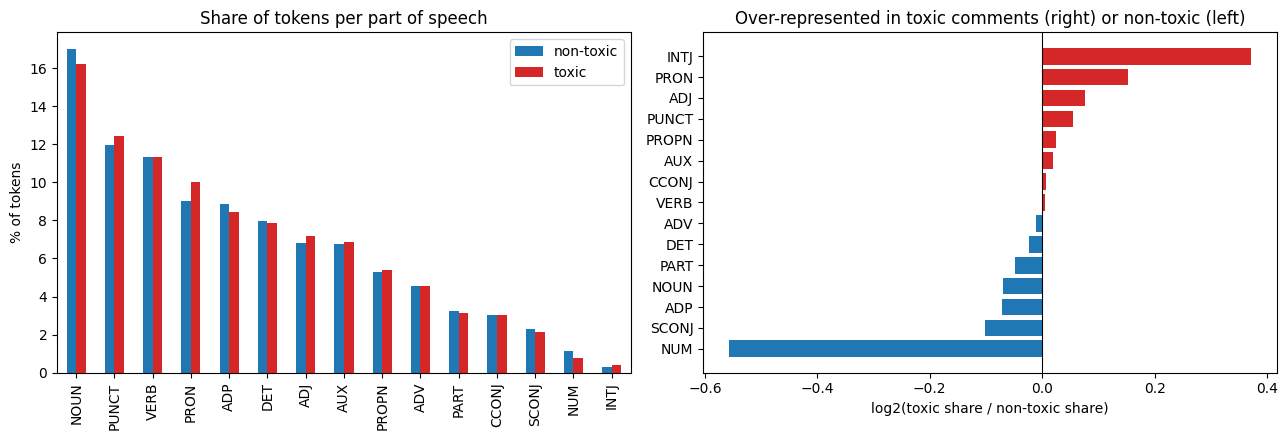

,non-toxic,toxic,log2 ratio
NOUN,0.1703,0.1623,-0.0701
PUNCT,0.1198,0.1245,0.0557
VERB,0.1131,0.1134,0.0045
PRON,0.0900,0.1000,0.1527
ADP,0.0889,0.0846,-0.0718
DET,0.0797,0.0784,-0.0227
ADJ,0.0679,0.0716,0.0763
AUX,0.0678,0.0686,0.0186
PROPN,0.0531,0.0540,0.0247
ADV,0.0457,0.0454,-0.0103


In [119]:
def pos_shares(docs):
    counts = Counter(token.pos_ for doc in docs for token in doc if not token.is_space)
    return pd.Series(counts) / sum(counts.values())


def docs_of_class(class_name):
    return [doc for doc, name in zip(eda_docs, eda_names) if name == class_name]


pos_profile = pd.DataFrame({name: pos_shares(docs_of_class(name)) for name in CLASS_NAMES.values()}).fillna(0)
pos_profile = pos_profile[pos_profile.min(axis=1) > 0.002].sort_values("non-toxic", ascending=False)
pos_profile["log2 ratio"] = np.log2(pos_profile["toxic"] / pos_profile["non-toxic"])

fig, (ax_share, ax_ratio) = plt.subplots(1, 2, figsize=(13, 4.5))
pos_profile[["non-toxic", "toxic"]].mul(100).plot.bar(ax=ax_share, color=["tab:blue", "tab:red"])
ax_share.set_ylabel("% of tokens")
ax_share.set_title("Share of tokens per part of speech")
ratio = pos_profile["log2 ratio"].sort_values()
ax_ratio.barh(ratio.index, ratio, color=np.where(ratio > 0, "tab:red", "tab:blue"))
ax_ratio.axvline(0, color="black", linewidth=0.8)
ax_ratio.set_xlabel("log2(toxic share / non-toxic share)")
ax_ratio.set_title("Over-represented in toxic comments (right) or non-toxic (left)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pos_profile.png", dpi=150)
plt.show()
display(pos_profile.round(4))

**How to read it:** the left chart shows what share of all tokens are nouns, verbs, pronouns and so on, for each
class. The right chart compares the two classes directly. A bar to the right means that word type is more common in
toxic comments. The scale is log2, so +0.37 for interjections (INTJ: words like "oh", "yes", "lol") means about 30%
more common, and -0.56 for numbers (NUM) means about a third less common.

**What this shows:** both classes are built from almost the same mix of word types; most bars are close to 0. The
clearest differences are more interjections and pronouns in toxic comments, and fewer numbers. Harmless comments more
often argue with figures, while toxic ones react and address people directly.

In [120]:
def top_words(docs, pos, n=15):
    counts = Counter(token.lower_ for doc in docs for token in doc if token.pos_ == pos)
    return [f"{word} ({count})" for word, count in counts.most_common(n)]


display(pd.DataFrame({f"{name}: adjectives": top_words(docs_of_class(name), "ADJ") for name in CLASS_NAMES.values()}
                     | {f"{name}: pronouns": top_words(docs_of_class(name), "PRON") for name in CLASS_NAMES.values()}))

,non-toxic: adjectives,toxic: adjectives,non-toxic: pronouns,toxic: pronouns
0,more (302),stupid (277),it (1814),you (2234)
1,other (248),more (257),i (1781),it (1658)
2,many (220),other (228),you (1620),i (1552)
3,good (217),good (176),that (1055),that (1105)
4,same (166),many (174),they (1002),they (1046)
5,- (116),white (165),we (740),he (964)
6,right (112),same (146),he (610),your (749)
7,own (110),own (131),what (605),what (674)
8,free (107),black (123),their (591),who (622)
9,much (105),right (122),who (550),we (591)


**What this shows:** the 15 most common adjectives and pronouns in each class, with counts. "stupid" tops the toxic
list, and "ignorant" and "ridiculous" appear further down. "white" and "black" are in the toxic top ten but missing
from the non-toxic top fifteen. "you" is the most common pronoun in toxic comments and only third in harmless ones.
The identity words are an early warning: if they lean toxic in the training data, the models may learn to treat them
as toxic. Section 10 tests this.

### 4.3 Where the tagger struggles

spaCy's tagger was trained mostly on edited text, and comments are not edited. One visible weak spot is shouting. The
check below looks at adjectives, verbs and adverbs: words that the sample contains in normal case at least five times
and that are usually tagged `ADJ`, `VERB` or `ADV` there. It then counts how often the ALL-CAPS version of the same
word gets a different tag. Nouns are left out because many ALL-CAPS nouns are acronyms ("US", or "GET" for Hawaii's
General Excise Tax) that really are proper nouns.

In [121]:
CONTENT_TAGS = {"ADJ", "VERB", "ADV"}
TAGGING_EXAMPLE_WORDS = ["EXACTLY", "WORSE", "KNEW"]


def is_shouted(token):
    return token.is_alpha and token.is_upper and len(token) > 2


def is_normal_case(token):
    return token.is_alpha and not token.is_upper


def usual_tags(docs, min_count=5):
    tags = defaultdict(Counter)
    for doc in docs:
        for token in doc:
            if is_normal_case(token):
                tags[token.lower_][token.pos_] += 1
    return {word: counts.most_common(1)[0][0] for word, counts in tags.items() if counts.total() >= min_count}


def tag_disagreements(docs, reference_tags, select):
    rows = []
    for doc in docs:
        for token in doc:
            if select(token) and token.lower_ in reference_tags:
                rows.append({"word": token.text, "tag": token.pos_, "usual tag": reference_tags[token.lower_],
                             "context": token.sent.text[:120]})
    table = pd.DataFrame(rows)
    return table.assign(differs=table["tag"] != table["usual tag"])


reference_tags = {word: tag for word, tag in usual_tags(eda_docs).items() if tag in CONTENT_TAGS}
shouted = tag_disagreements(eda_docs, reference_tags, is_shouted)
normal = tag_disagreements(eda_docs, reference_tags, is_normal_case)
print(f"Tag differs from the word's usual tag: {shouted['differs'].mean():.1%} of {len(shouted):,} ALL-CAPS words, "
      f"{normal['differs'].mean():.1%} of {len(normal):,} normal-case words")
display(shouted[shouted["differs"]]["tag"].value_counts().head(5).to_frame("tag given to ALL-CAPS words that differ"))
display(shouted[shouted["differs"] & shouted["word"].isin(TAGGING_EXAMPLE_WORDS)].drop_duplicates("word"))

Tag differs from the word's usual tag: 39.8% of 523 ALL-CAPS words, 11.7% of 69,044 normal-case words


,tag given to ALL-CAPS words that differ
tag,
PROPN,140
NOUN,42
ADJ,8
VERB,7
ADV,6


,word,tag,usual tag,context,differs
21,EXACTLY,PROPN,ADV,We are not free thinkers unless WE THINK EXACTLY AS YOU DO.,True


**What this shows:** spaCy gives a shouted adjective, verb or adverb a different tag about 40% of the time, against
about 12% for the same words written normally. Usually it calls the shouted word a proper noun (PROPN), as if
"EXACTLY" were a name. Tools trained on edited text are less reliable on online comments, and least reliable on the
angry parts. The POS profile above is still fine for comparing the two classes, because ALL-CAPS words make up only
about 1.6% of words in both.

### 4.4 Comment length in DistilBERT tokens

The transformer reads at most `MAX_LENGTH` word pieces per comment and cuts off the rest. This plot checks how much text
that cut-off loses.

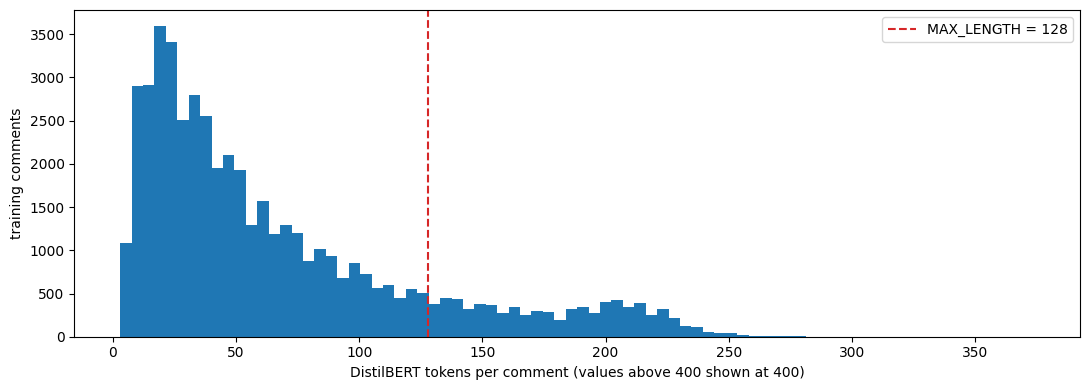

Median 47 tokens, 90th percentile 162. 84.6% of comments fit in 128 tokens.
Toxic share: 8.1% of comments that fit, 6.7% of longer comments


In [122]:
train_token_counts = np.array([len(ids) for ids in tokenizer(train["text_clean"].tolist())["input_ids"]])

fig, ax = plt.subplots()
ax.hist(np.minimum(train_token_counts, 400), bins=80, color="tab:blue")
ax.axvline(MAX_LENGTH, color="tab:red", linestyle="--", label=f"MAX_LENGTH = {MAX_LENGTH}")
ax.set_xlabel("DistilBERT tokens per comment (values above 400 shown at 400)")
ax.set_ylabel("training comments")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "token_lengths.png", dpi=150)
plt.show()
fits = train_token_counts <= MAX_LENGTH
print(f"Median {np.median(train_token_counts):.0f} tokens, "
      f"90th percentile {np.percentile(train_token_counts, 90):.0f}. "
      f"{fits.mean():.1%} of comments fit in {MAX_LENGTH} tokens.")
print(f"Toxic share: {train.loc[fits, 'label'].mean():.1%} of comments that fit, "
      f"{train.loc[~fits, 'label'].mean():.1%} of longer comments")

**What this shows:** a typical comment is 47 word pieces long, and 85% of comments fit into the 128-token limit. Only
the long tail to the right of the red line gets cut off. Long comments are a little less often toxic (6.7% against
8.1%), so cutting them short should cost little. Section 8.4 checks this.

### 4.5 Modelling decisions

The exploration led to six concrete decisions:

1. **Keep stopwords and pronouns.** Toxic comments address people ("you", "your"), and those words are on most
   stopword lists. Removing them would delete one of the clearest differences between the classes.
2. **Use word pairs in the baseline.** Bigrams let TF-IDF see "you are" or "shut up" as one unit instead of two
   unrelated words.
3. **Do not use length as a feature.** Both classes have the same typical length, so it would not help.
4. **Use the uncased DistilBERT.** Shouting is equally rare in both classes, so losing capital letters costs little.
5. **Do not feed POS tags to the models.** The tagger is least reliable on shouted words, and the POS profile only
   differs slightly between classes.
6. **Cut comments at 128 tokens.** This keeps 85% of comments whole and keeps training under an hour on a laptop;
   DistilBERT could read up to 512, at a much higher cost for the long comments.

Three findings shape the evaluation instead: errors will cluster around the 0.5 threshold because labels there are
close votes (checked in 8.4), long comments may suffer from the cut (checked in 8.4), and identity words already lean
toxic in the training data (tested in section 10).

## 5. Baseline: TF-IDF and logistic regression

A baseline is a simple, well-understood model. It shows what "good enough" looks like before trying anything
expensive, and every later model has to beat it to be worth its cost.

**How it works.** TF-IDF turns each comment into a long list of numbers, one per word or word pair in the vocabulary.
A word gets a high number when it appears in this comment but is rare across all comments, so "idiot" counts for more
than "the". Logistic regression then learns one weight per word or word pair and adds the weights of a comment up into
a score between 0 and 1.

**Settings.**

- `ngram_range=(1, 2)`: single words and word pairs (bigrams), so "shut up" stays together.
- `min_df=3`: terms that appear in fewer than three comments are ignored. They are mostly typos and names.
- `sublinear_tf=True`: a word used ten times in one comment does not count ten times as much.
- `class_weight="balanced"`: the 8% toxic comments get as much total weight in training as the 92% harmless ones, so
  the model cannot score well by ignoring them.
- `solver="liblinear"`: in a first attempt, scikit-learn's default solver stopped too early on this data and its
  results jumped around from one setting to the next. `liblinear` finishes properly in about a second.

**Tuning.** `C` controls how freely the model may fit the training data: a higher `C` means fewer restrictions. It is
chosen by PR-AUC on the validation set. The threshold is then set to the score that gives the best F1 on validation.
The test set is used only after both choices are fixed.

In [123]:
def fit_tfidf_logreg(texts, labels, c):
    model = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True),
        LogisticRegression(C=c, class_weight="balanced", solver="liblinear"),
    )
    return model.fit(texts, labels)


def toxic_proba(model, texts):
    return model.predict_proba(texts)[:, 1]


c_search = {c: fit_tfidf_logreg(train["text_clean"], train["label"], c) for c in TFIDF_C_GRID}
c_scores = {c: average_precision_score(validation["label"], toxic_proba(model, validation["text_clean"]))
            for c, model in c_search.items()}
best_c = max(c_scores, key=c_scores.get)
baseline = c_search[best_c]
display(pd.Series(c_scores).rename_axis("C").to_frame("validation PR-AUC").round(4))
print(f"Chosen C = {best_c}")

,validation PR-AUC
C,
1,0.5618
4,0.5768
16,0.5755
64,0.5647


Chosen C = 4


**What this shows:** C = 4 gives the best validation PR-AUC (0.577). A smaller C holds the model back too much. A
larger C lets it memorise rare word pairs from the training comments, and the score drops again. The best value is one
of the middle values tested, so searching further would most likely not help.

To test whether cleaning helps, the same pipeline with the chosen `C` is trained on the raw text:

In [124]:
baseline_raw = fit_tfidf_logreg(train["text"], train["label"], best_c)
display(pd.DataFrame({
    "vocabulary size": [len(baseline_raw[0].vocabulary_), len(baseline[0].vocabulary_)],
    "validation PR-AUC": [average_precision_score(validation["label"], toxic_proba(baseline_raw, validation["text"])),
                          c_scores[best_c]],
}, index=["raw text", "cleaned text"]).round(4))

,vocabulary size,validation PR-AUC
raw text,142311,0.5762
cleaned text,141495,0.5768


**What this shows:** cleaning removes about 800 terms from the vocabulary (mostly one-off pieces of links) and changes
the validation PR-AUC only in the fourth decimal (0.5762 against 0.5768). For this model the cleaning does no harm
but makes no real difference either. TF-IDF already ignores line breaks, and only 3% of comments contain a link. The
cleaned text is kept because it is tidier and costs nothing.

In [125]:
def best_f1_threshold(labels, probabilities):
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])


def score_predictions(labels, probabilities, threshold):
    predictions = probabilities >= threshold
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions),
        "F1": f1_score(labels, predictions),
        "ROC-AUC": roc_auc_score(labels, probabilities),
        "PR-AUC": average_precision_score(labels, probabilities),
        "threshold": threshold,
    }


baseline_threshold = best_f1_threshold(validation["label"], toxic_proba(baseline, validation["text_clean"]))
test_probabilities = {"always non-toxic": np.zeros(len(test)),
                      "TF-IDF + LR": toxic_proba(baseline, test["text_clean"])}
thresholds = {"always non-toxic": 0.5, "TF-IDF + LR": baseline_threshold}
baseline_metrics = pd.DataFrame({name: score_predictions(test["label"], probabilities, thresholds[name])
                                 for name, probabilities in test_probabilities.items()}).T
display(baseline_metrics.round(3))

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,threshold
always non-toxic,0.920,0.000,0.000,0.000,0.500,0.080,0.500
TF-IDF + LR,0.923,0.518,0.591,0.552,0.898,0.588,0.444


**What this shows:** the "always non-toxic" row is the trap that accuracy sets: 92% accuracy without finding a single
toxic comment. The baseline is barely more accurate (92.3%), but it finds 59% of the toxic comments (recall 0.59), and
about half of what it flags is really toxic (precision 0.52). Its PR-AUC of 0.59 is far above the 0.08 of a random
order, and also far from perfect. This is the bar DistilBERT has to clear.

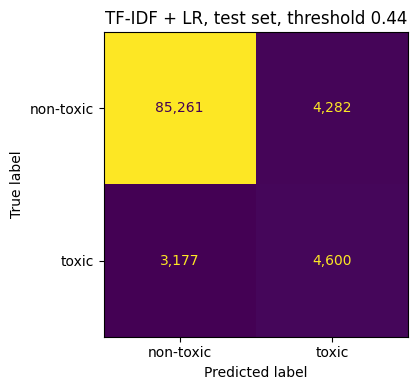

In [126]:
def plot_confusion_matrix(ax, model_name):
    flagged = test_probabilities[model_name] >= thresholds[model_name]
    ConfusionMatrixDisplay.from_predictions(test["label"], flagged, ax=ax, colorbar=False, values_format=",",
                                            display_labels=list(CLASS_NAMES.values()))
    ax.set_title(f"{model_name}, test set, threshold {thresholds[model_name]:.2f}")


fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(ax, "TF-IDF + LR")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_baseline.png", dpi=150)
plt.show()

**How to read it:** rows are the true labels, columns are what the model decided. The top-left cell counts harmless
comments correctly let through, and the bottom-right cell counts toxic comments correctly flagged. The other two cells
are mistakes.

**What this shows:** of the 7,777 toxic test comments the baseline catches 4,600 and misses 3,177. It also flags 4,282
harmless comments by mistake, almost as many false alarms as correct hits. A moderator working from this queue would
spend about half of their time on harmless comments.

Each word or word pair in the baseline has one weight: positive weights raise the
toxic score, negative ones lower it. One caveat: a weight is learned together with all the others, so words that
usually appear together share the credit between them.

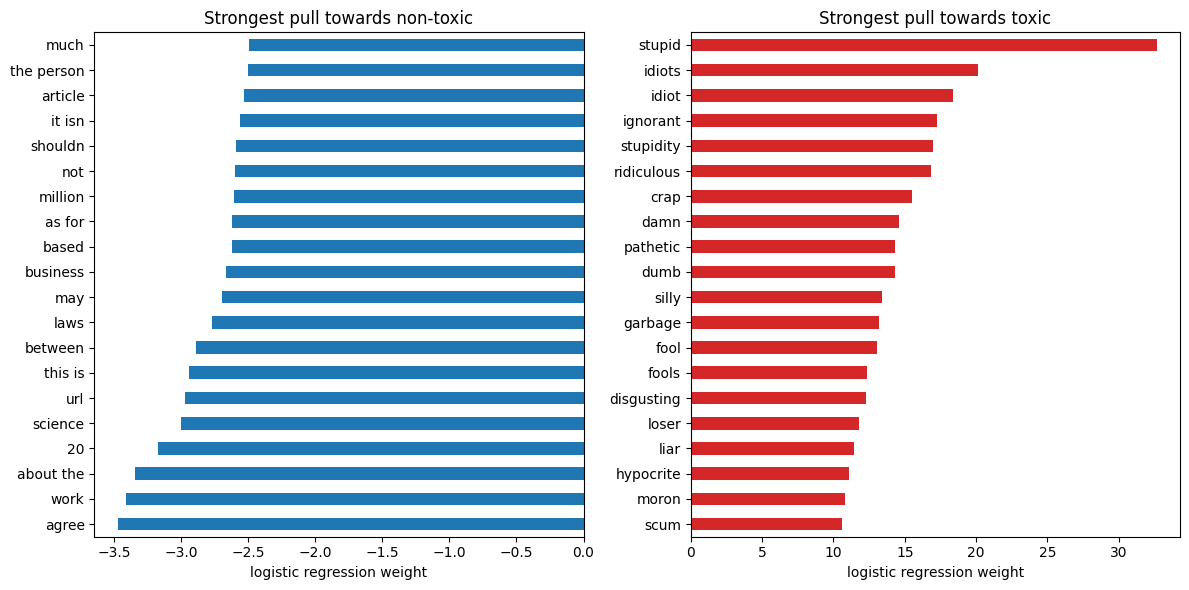

In [127]:
vectorizer, classifier = baseline[0], baseline[1]
term_weights = pd.Series(classifier.coef_[0], index=vectorizer.get_feature_names_out()).sort_values()

fig, (ax_clean, ax_toxic) = plt.subplots(1, 2, figsize=(12, 6))
term_weights.head(20).plot.barh(ax=ax_clean, color="tab:blue", title="Strongest pull towards non-toxic")
term_weights.tail(20).plot.barh(ax=ax_toxic, color="tab:red", title="Strongest pull towards toxic")
for ax in (ax_clean, ax_toxic):
    ax.set_xlabel("logistic regression weight")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "baseline_term_weights.png", dpi=150)
plt.show()

**What this shows:** the toxic side is a list of insults: "stupid", "idiot", "ignorant", "moron", "scum". The
harmless side is made of ordinary, factual words: "agree", "science", "laws", "business", numbers like "20" and
"million", and the `URL` placeholder for links. This matches section 4, where harmless comments used more numbers.

The list also explains the baseline's weak spot. Words like "ridiculous", "silly", "pathetic" and "garbage" pull
strongly towards toxic, although people often aim them at an *idea* or an *article* ("a ridiculous analogy")
and attack nobody. The baseline cannot tell the difference, because it only counts words.

## 6. Transformer: fine-tuned DistilBERT

**What fine-tuning means.** A transformer like BERT has already read billions of words of English and learned how
words relate to each other in context. Fine-tuning keeps all of that knowledge and adds one small output layer, then
continues training the whole model for a short time on our labelled comments. The model does not have to learn English
from 50,000 comments; it only has to learn what "toxic" means in this data.

**Model choice.** `distilbert-base-uncased` is a smaller copy of BERT, trained to imitate the full model. It is
much smaller and faster than the full BERT and keeps most of its accuracy. That makes it the strongest model that fine-tunes on 50,000 comments in under an
hour on a laptop GPU.

The *uncased* version lowercases everything, so it cannot see shouting. Section 4.1 showed that ALL-CAPS words are
about as common in toxic as in non-toxic comments (1.6% against 1.7% of words), so little is lost. Its tokenizer splits
words it does not know into known pieces ("unbelievably" becomes `un`, `##bel`, `##ie`, `##va`, `##bly`). This helps
with typos and invented insults, which a TF-IDF vocabulary would simply drop.

**Fine-tuning setup.**

| Setting | Value | Reason |
|---|---|---|
| learning rate | 2e-5 | a common value for fine-tuning BERT-style models (usual range 2e-5 to 5e-5) |
| batch size | 32 | a common size; fits in 16 GB of shared memory |
| epochs | 2 | fine-tuning usually needs 2 to 4; the checkpoint with the best validation PR-AUC is kept |
| max length | 128 tokens | covers 85% of comments whole (section 4.4) |
| warmup | first 6% of steps | avoids large updates while the new classification layer is still random |
| weight decay | 0.01 | standard light regularisation for transformer fine-tuning |
| loss | plain cross-entropy | class imbalance is handled by the validation threshold, exactly as for the baseline |
| checkpoint choice | best validation PR-AUC, checked every 500 steps | the same metric the baseline was tuned on |

In [128]:
def to_token_dataset(comments):
    dataset = Dataset.from_dict({"text": comments["text_clean"].tolist(), "label": comments["label"].tolist()})
    return dataset.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH),
                       batched=True, remove_columns=["text"])


def toxic_probabilities(logits, temperature=1.0):
    return torch.softmax(torch.as_tensor(logits, dtype=torch.float32) / temperature, dim=-1)[:, 1].numpy()


def validation_pr_auc(evaluation):
    return {"pr_auc": average_precision_score(evaluation.label_ids, toxic_probabilities(evaluation.predictions))}


def training_arguments():
    return TrainingArguments(
        output_dir=str(CHECKPOINTS_DIR), seed=SEED, report_to="none", disable_tqdm=True,
        learning_rate=LEARNING_RATE, num_train_epochs=EPOCHS, weight_decay=WEIGHT_DECAY, warmup_steps=WARMUP_RATIO,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=4 * BATCH_SIZE,
        eval_strategy="steps", eval_steps=EVAL_EVERY_STEPS, save_strategy="steps", save_steps=EVAL_EVERY_STEPS,
        logging_steps=LOG_EVERY_STEPS, load_best_model_at_end=True, metric_for_best_model="pr_auc",
        save_total_limit=1, dataloader_pin_memory=False,
    )


def fine_tune_distilbert():
    trainer = Trainer(
        model=AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2),
        args=training_arguments(), train_dataset=to_token_dataset(train), eval_dataset=to_token_dataset(validation),
        processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=validation_pr_auc,
    )
    trainer.remove_callback(PrinterCallback)
    trainer.train()
    trainer.save_model(MODEL_DIR)
    TRAINING_LOG_PATH.write_text(json.dumps(trainer.state.log_history, indent=2))
    shutil.rmtree(CHECKPOINTS_DIR)

Training takes 40 to 50 minutes on an M1 Pro. It runs only when no saved model exists, so re-running the notebook
reuses the model in `models/distilbert_toxicity/`. Delete that folder to train again from scratch.

In [129]:
if not MODEL_DIR.exists():
    fine_tune_distilbert()
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(DEVICE).eval()
training_log = json.loads(TRAINING_LOG_PATH.read_text())
print(f"Training time: {training_log[-1]['train_runtime'] / 60:.0f} minutes on {DEVICE}")

Training time: 51 minutes on mps


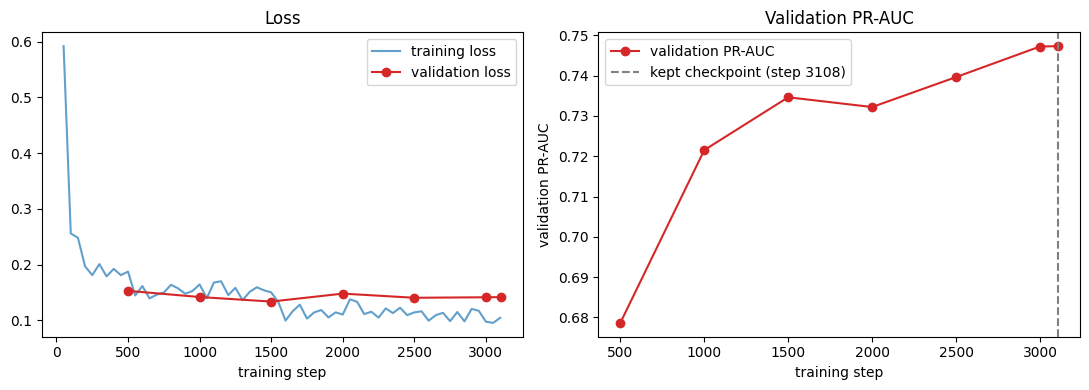

Best validation PR-AUC 0.7473 at step 3108 of 3108


In [130]:
def log_series(log, key):
    return pd.Series({entry["step"]: entry[key] for entry in log if key in entry}, name=key)


validation_curve = log_series(training_log, "eval_pr_auc")
best_step = validation_curve.idxmax()

fig, (ax_loss, ax_score) = plt.subplots(1, 2)
log_series(training_log, "loss").plot(ax=ax_loss, label="training loss", color="tab:blue", alpha=0.7)
log_series(training_log, "eval_loss").plot(ax=ax_loss, label="validation loss", color="tab:red", marker="o")
ax_loss.set_xlabel("training step")
ax_loss.legend()
ax_loss.set_title("Loss")
validation_curve.plot(ax=ax_score, color="tab:red", marker="o", label="validation PR-AUC")
ax_score.axvline(best_step, color="grey", linestyle="--", label=f"kept checkpoint (step {best_step})")
ax_score.set_xlabel("training step")
ax_score.set_ylabel("validation PR-AUC")
ax_score.legend()
ax_score.set_title("Validation PR-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_curves.png", dpi=150)
plt.show()
print(f"Best validation PR-AUC {validation_curve.max():.4f} at step {best_step} of {max(validation_curve.index)}")

**How to read it:** the left chart shows the *loss*, the model's own measure of how wrong it is (lower is better), on
the training comments (blue, every 50 steps) and on the validation comments (red, every 500 steps). The right chart
shows the validation PR-AUC. One *epoch*, a full pass through the 50,000 training comments, is about 1,550 steps.

**What this shows:** the training loss drops fast in the first 100 steps and then keeps sinking slowly, from an
average of 0.16 in the first epoch to 0.11 in the second. The validation loss stops improving after the first epoch
(lowest 0.134 at step 1,500), but the validation PR-AUC still creeps up, to 0.747 at the end. So in the second epoch
the model starts to memorise its training comments and becomes overconfident on some validation comments, which
raises the loss. It still ranks the validation comments slightly better, and ranking is what the queue needs. A third
epoch would most likely add little. The checkpoint with the best validation PR-AUC is kept, which here is the last one.

The printed 51 minutes include about 25 minutes in which a second copy of this notebook was training on the same GPU;
alone, training takes about 40 minutes.

Test-set results for both models follow in section 7, side by side.

## 7. Comparison on the test set

Both models are scored on the same 97,320 test comments, which neither has seen before. Each model's threshold was
fixed on the validation set first. PR-AUC and ROC-AUC do not need a threshold at all.

One extra column is meant for moderators. "Precision at 80% recall" is the share of flagged comments that are really
toxic when the flagged comments include 4 out of 5 toxic comments. The higher this number, the less time moderators
waste on harmless comments.

In [131]:
def predict_logits(texts, batch_size=4 * BATCH_SIZE):
    order = np.argsort([len(text) for text in texts])
    batches = []
    for start in range(0, len(texts), batch_size):
        batch_texts = [texts[index] for index in order[start:start + batch_size]]
        encoded = tokenizer(batch_texts, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors="pt")
        with torch.no_grad():
            batches.append(model(**encoded.to(DEVICE)).logits.float().cpu().numpy())
    return np.concatenate(batches)[np.argsort(order)]


def precision_at_recall(labels, probabilities, target_recall=0.8):
    precision, recall, _ = precision_recall_curve(labels, probabilities)
    return float(precision[recall >= target_recall].max())


validation_logits = predict_logits(validation["text_clean"].tolist())
test_logits = predict_logits(test["text_clean"].tolist())
thresholds["DistilBERT"] = best_f1_threshold(validation["label"], toxic_probabilities(validation_logits))
test_probabilities["DistilBERT"] = toxic_probabilities(test_logits)
assert all(len(probabilities) == len(test) for probabilities in test_probabilities.values())

comparison = pd.DataFrame({
    name: score_predictions(test["label"], probabilities, thresholds[name])
    | {"precision at 80% recall": precision_at_recall(test["label"], probabilities)}
    for name, probabilities in test_probabilities.items()
}).T
display(comparison.round(3))

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,threshold,precision at 80% recall
always non-toxic,0.920,0.000,0.000,0.000,0.500,0.080,0.500,0.080
TF-IDF + LR,0.923,0.518,0.591,0.552,0.898,0.588,0.444,0.292
DistilBERT,0.945,0.650,0.668,0.659,0.946,0.728,0.289,0.498


**What this shows:** DistilBERT is better on every measure: F1 0.66 against 0.55, PR-AUC 0.73 against 0.59 and
ROC-AUC 0.95 against 0.90. The most practical number is the last column. If the queue must contain 4 out of 5 toxic
comments, half of DistilBERT's flagged comments are really toxic (0.50), against fewer than a third for the baseline
(0.29). In everyday terms: with DistilBERT a moderator reads about one harmless comment for each toxic one, with the
baseline more than two.

DistilBERT's threshold (0.29) is much lower than the baseline's (0.44). It was trained without class weights, so it
gives toxic comments lower scores overall, and the best F1 on validation happens to sit at a lower cut-off. The value
of a threshold only matters relative to the model's own scores.

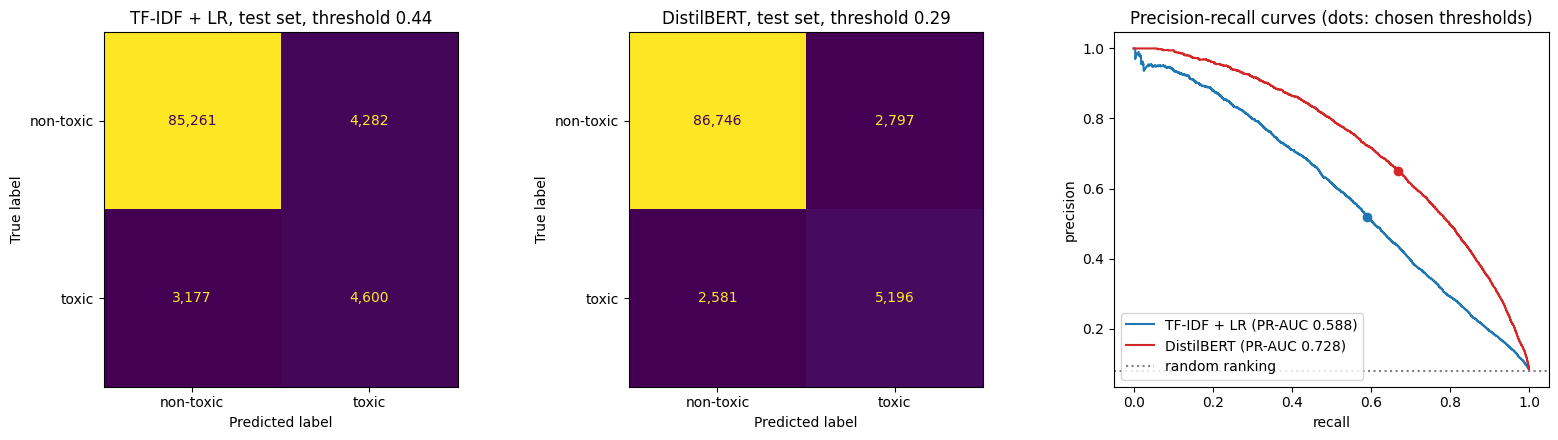

In [132]:
MODELS = ["TF-IDF + LR", "DistilBERT"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, MODELS):
    plot_confusion_matrix(ax, name)
for name, colour in zip(MODELS, ["tab:blue", "tab:red"]):
    precision, recall, _ = precision_recall_curve(test["label"], test_probabilities[name])
    axes[2].plot(recall, precision, color=colour, label=f"{name} (PR-AUC {comparison.loc[name, 'PR-AUC']:.3f})")
    axes[2].scatter(comparison.loc[name, "recall"], comparison.loc[name, "precision"], color=colour, zorder=3)
axes[2].axhline(test["label"].mean(), color="grey", linestyle=":", label="random ranking")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
axes[2].set_title("Precision-recall curves (dots: chosen thresholds)")
axes[2].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_comparison.png", dpi=150)
plt.show()

**How to read it:** the two left panels are confusion matrices, read as in section 5. The right panel shows every
possible threshold at once. Moving along a curve from left to right, the model flags more comments: it finds more
toxic ones (recall goes up) but its flags become less reliable (precision goes down). The dots mark the thresholds
actually chosen. A curve that lies higher is better everywhere.

**What this shows:** DistilBERT catches 5,196 of the 7,777 toxic comments (the baseline 4,600) *and* raises fewer
false alarms (2,797 against 4,282). Its curve lies above the baseline's at every threshold, so whatever trade-off a site
chooses, DistilBERT does better. Still, at the chosen threshold it misses one toxic comment in three (2,581).

A bootstrap checks whether the gap between the two models could be luck, caused by which comments happened to end up
in the test set. It builds 1,000 new test sets, each drawn at random from the real one (the same comment may be drawn
more than once). It measures the gap on each of them. If the middle 95% of those 1,000 gaps stays above 0, the
difference is very unlikely to be luck.

In [133]:
N_BOOTSTRAP = 1_000


def bootstrap_difference(scores_baseline, scores_distilbert, metric):
    rng = np.random.default_rng(SEED)
    labels = test["label"].to_numpy()
    differences = []
    for _ in range(N_BOOTSTRAP):
        rows = rng.integers(0, len(labels), len(labels))
        differences.append(metric(labels[rows], scores_distilbert[rows]) - metric(labels[rows], scores_baseline[rows]))
    return np.percentile(differences, [2.5, 97.5])


flags = {name: test_probabilities[name] >= thresholds[name] for name in MODELS}
bootstrap = pd.DataFrame({
    "F1": bootstrap_difference(flags["TF-IDF + LR"], flags["DistilBERT"], f1_score),
    "PR-AUC": bootstrap_difference(test_probabilities["TF-IDF + LR"], test_probabilities["DistilBERT"],
                                   average_precision_score),
}, index=["2.5%", "97.5%"]).T
observed_difference = comparison.loc["DistilBERT", ["F1", "PR-AUC"]] - comparison.loc["TF-IDF + LR", ["F1", "PR-AUC"]]
bootstrap.insert(0, "difference", observed_difference)
display(bootstrap.round(4))

,difference,2.5%,97.5%
F1,0.1067,0.0980,0.1149
PR-AUC,0.1398,0.1314,0.1484


**What this shows:** DistilBERT's F1 is 0.107 higher, and across the 1,000 resampled test sets the gap stays between
0.098 and 0.115. For PR-AUC the gap is 0.140, between 0.131 and 0.148. Neither range comes anywhere near 0, so the
difference is not luck.

In [134]:
predictions = test[["text_clean", "toxicity", "label"]].assign(
    tfidf_lr_probability=test_probabilities["TF-IDF + LR"],
    distilbert_probability=test_probabilities["DistilBERT"],
    tfidf_lr_flag=flags["TF-IDF + LR"].astype(int),
    distilbert_flag=flags["DistilBERT"].astype(int),
)
predictions.to_parquet(PREDICTIONS_PATH)
results |= {"baseline C": best_c, "thresholds": thresholds, "test metrics": comparison.to_dict(orient="index"),
            "bootstrap 95% CI of DistilBERT minus TF-IDF + LR": bootstrap.to_dict(orient="index")}
print(f"Saved {len(predictions):,} test predictions to {PREDICTIONS_PATH}")

Saved 97,320 test predictions to test_predictions.parquet


**Verdict on H1 and the first success criterion.** H1 is supported: DistilBERT ranks toxic comments clearly better
than TF-IDF + logistic regression (PR-AUC 0.73 against 0.59). The first success criterion is met: its F1 of 0.66 is
above the target of 0.60, and the bootstrap range of the gap lies well above 0.

Context is the most likely reason for the gap. The baseline gives a word the same weight wherever it appears. DistilBERT reads each
word together with its neighbours, so "ridiculous" in "a ridiculous analogy" can count differently from "you are
ridiculous". The error analysis below shows that this works often, but not always.

The test predictions of both models are saved in `test_predictions.parquet` for anyone who wants to check them.

## 8. Error analysis

### 8.1 Curated examples

Numbers say how often a model is wrong, but only reading the comments shows *why*. The table below holds twelve test
comments: three toxic comments DistilBERT caught (TP), three harmless ones it correctly let through (TN), and then its
three most confident false alarms (FP) and its three most confident misses (FN). The confident mistakes teach the most,
because they show what the model is sure about and still gets wrong.

In [135]:
OUTCOME_NAMES = {(1, 1): "TP", (0, 0): "TN", (0, 1): "FP", (1, 0): "FN"}
predictions["outcome"] = [OUTCOME_NAMES[pair] for pair in zip(predictions["label"], predictions["distilbert_flag"])]


def curated_examples(per_outcome=3):
    by_outcome = predictions.groupby("outcome")
    return pd.concat([
        by_outcome.get_group("TP").sample(per_outcome, random_state=SEED),
        by_outcome.get_group("TN").sample(per_outcome, random_state=SEED),
        by_outcome.get_group("FP").nlargest(per_outcome, "distilbert_probability"),
        by_outcome.get_group("FN").nsmallest(per_outcome, "distilbert_probability"),
    ])


EXAMPLE_NOTES = {
    25382: "calls the opinion 'garbage' but argues the point; only 56% of annotators said toxic",
    1347: "violent metaphor ('raped financially') and angry punctuation",
    61482: "name-calling plus shouting ('STUCK on STUPID'); both models are sure",
    95207: "polite disagreement about climate and fires",
    88030: "'lunacy run amok' is harsh, but annotators and both models call it harmless",
    24227: "political argument that addresses 'you' without insulting anyone",
    9266: "'stupid' appears inside a real question; 46% of annotators still said toxic",
    30640: "praises Trump, then ends with 'people think he is an idiot'; the model reacts to 'idiot'",
    59935: "calls voters greedy and racist and Trump 'the idiot'; looks toxic, 40% of annotators agreed",
    91429: "one-word verdict 'Deplorable.' about a decision; an exact tie among annotators (0.50)",
    26787: "'idjits' is a misspelling of 'idiots' that the model never learned",
    44670: "sarcastic insult of a group ('Liberal brainless trust') without a strong word",
}

examples = curated_examples()
display(examples[["outcome", "toxicity", "tfidf_lr_probability", "distilbert_probability", "text_clean"]]
        .assign(note=examples.index.map(EXAMPLE_NOTES)).round(3))

,outcome,toxicity,tfidf_lr_probability,distilbert_probability,text_clean,note
25382,TP,0.559,0.281,0.971,This opinion is garbage. Why? Read how many times the author tells us May's motives. He does not know May's motives. Yet he proclaims them and builds his opinion around his projection of motive. C...,calls the opinion 'garbage' but argues the point; only 56% of annotators said toxic
1347,TP,0.721,0.567,0.976,Us hard working taxpayers continue to get raped financially by this liberal government!!! Sorry folks but every single person in this country has some form of injustice done to them - now does tha...,violent metaphor ('raped financially') and angry punctuation
61482,TP,0.840,0.997,0.988,"Gov. Iggy is socially naive. Besides, being STUCK on STUPID !",name-calling plus shouting ('STUCK on STUPID'); both models are sure
95207,TN,0.000,0.091,0.001,"I think you mean a fire ecosystem. And yes, that is true. But you can't deny the fact that the fire hazard is increasing at alarming rates and that the fires are more frequent and severe than they...",polite disagreement about climate and fires
88030,TN,0.000,0.026,0.008,"This is what I joking said Chin would do in my comment to the previous story about the new rules regarding close relationships. He is essential saying that Hawaiian ""hanai"" relationships are close...","'lunacy run amok' is harsh, but annotators and both models call it harmless"
24227,TN,0.000,0.169,0.006,"Do it, you have the votes in Congress if the entire GOP votes with you. Justice is always a social choice, it is legitimate to make sure that everyone has enough toys, which is not convenient if y...",political argument that addresses 'you' without insulting anyone
9266,FP,0.464,0.915,0.987,How do you know what is stupid though? Every rescue happens because of some failure. Which failures should the rescued pay for?,'stupid' appears inside a real question; 46% of annotators still said toxic
30640,FP,0.400,0.177,0.986,To show that Trump maybe the best bi-partisan choice the President-elect is set to meet Friday with North Dakota Sen. Heidi Heitkamp. It is rumored that the energy state democratic senator may get...,"praises Trump, then ends with 'people think he is an idiot'; the model reacts to 'idiot'"
59935,FP,0.400,0.876,0.986,This type of article is a dime a dozen. Where are the articles about those other Deplorables? All the upper middle class and upper class professionals and businesspeople who voted for Trump. Those...,"calls voters greedy and racist and Trump 'the idiot'; looks toxic, 40% of annotators agreed"
91429,FN,0.500,0.062,0.001,"And then after ten years finally decided to grant a small increase, but only if you give up your transit pass. Deplorable.",one-word verdict 'Deplorable.' about a decision; an exact tie among annotators (0.50)


**What this shows:**

- **The hits (TP)** contain a clear insulting word ("garbage", "STUPID") or a violent image ("raped financially").
  In the first one DistilBERT is far more certain (0.97) than the annotators were (0.56), while the baseline did not
  flag it at all (0.28).
- **The correct passes (TN)** are ordinary arguments. One contains "lunacy run amok" and still scores 0.008, so
  DistilBERT does not react to every harsh word.
- **The confident false alarms (FP)** all contain "stupid" or "idiot". Two of them would look toxic to many readers,
  and 40 to 46% of the annotators agreed. These are disagreements about the label as much as model mistakes.
- **The confident misses (FN)** contain no common insult: a one-word verdict ("Deplorable."), a misspelling ("idjits")
  and a sarcastic group label ("brainless trust"). Two of the three had an exact tie among annotators (0.50).

The pattern: DistilBERT relies heavily on well-known insulting words. It struggles with misspelled insults and with
toxicity that is only implied.

### 8.2 Where the two models disagree

In [136]:
display(pd.crosstab(predictions["tfidf_lr_flag"] == predictions["label"],
                     predictions["distilbert_flag"] == predictions["label"],
                     rownames=["TF-IDF + LR correct"], colnames=["DistilBERT correct"], margins=True))

DistilBERT correct,False,True,All
TF-IDF + LR correct,,,
False,3388,4071,7459
True,1990,87871,89861
All,5378,91942,97320


**What this shows:** both models are right on 87,871 comments (90%). DistilBERT fixes 4,071 of the baseline's
mistakes, but it also gets 1,990 comments wrong that the simple model got right, and 3,388 comments fool both. The two
models make partly different mistakes. The 3,388 shared mistakes are the hard core: comments whose label probably
cannot be learned from the words alone.

### 8.3 Fifty errors read and tagged by hand

Twelve examples can be misleading, so this step looks at more. 25 random false alarms and 25 random misses from
DistilBERT were each read and given the one category that best explains the mistake. The tags are one reader's
judgement, and with 50 comments the shares are rough. They still show which kinds of mistakes are common and which
are rare.

In [137]:
STRONG_WORDS_NO_TARGET = "strong words, no personal attack"
UNCOUNTED_INSULT = "insult the label calls harmless"
SARCASM_OR_QUOTE = "sarcasm or quote"
IDENTITY_MENTION = "identity mention"
UNTARGETED_PROFANITY = "profanity not aimed at anyone"
INDIRECT_INSULT = "indirect insult, no rude words"
UNCLEAR_LABEL = "label unclear"
SEXUAL_CONTENT = "sexual content"
MISSED_CLEAR_INSULT = "clear insult the model missed"
CUT_OFF = "toxic part after token 128"

ERROR_TAGS = {
    **dict.fromkeys([72525, 25280, 90378, 57546, 47046, 91107, 52471, 14381, 26592, 96181], STRONG_WORDS_NO_TARGET),
    **dict.fromkeys([43603, 74717, 84453, 61874, 46065, 45217, 44588, 29442, 78984], UNCOUNTED_INSULT),
    **dict.fromkeys([50528, 92157, 49617, 24886, 41619], SARCASM_OR_QUOTE),
    **dict.fromkeys([59697, 18228, 52681, 94323, 57245, 18678], IDENTITY_MENTION),
    **dict.fromkeys([74518], UNTARGETED_PROFANITY),
    **dict.fromkeys([11579, 62938, 83767, 10534, 71330, 40869, 70792], INDIRECT_INSULT),
    **dict.fromkeys([28549, 90719, 83775, 76877, 66003], UNCLEAR_LABEL),
    **dict.fromkeys([96880, 55649, 91650, 38322], SEXUAL_CONTENT),
    **dict.fromkeys([26787, 12668], MISSED_CLEAR_INSULT),
    **dict.fromkeys([34850], CUT_OFF),
}

error_sample = pd.concat([predictions[predictions["outcome"] == outcome].sample(25, random_state=SEED)
                          for outcome in ["FP", "FN"]])
error_sample["category"] = error_sample.index.map(ERROR_TAGS)
assert error_sample["category"].notna().all(), "every sampled error needs a tag"
error_counts = pd.crosstab(error_sample["category"], error_sample["outcome"], margins=True, margins_name="total")
display(pd.concat([error_counts.drop("total").sort_values("total", ascending=False), error_counts.loc[["total"]]]))

outcome,FN,FP,total
category,,,
"strong words, no personal attack",0,10,10
insult the label calls harmless,0,9,9
"indirect insult, no rude words",7,0,7
identity mention,4,2,6
label unclear,5,0,5
sarcasm or quote,2,3,5
sexual content,4,0,4
clear insult the model missed,2,0,2
profanity not aimed at anyone,0,1,1


**What the categories mean:**

| Category | Meaning | Example from the sample |
|---|---|---|
| strong words, no personal attack | harsh words about an idea, article or film, nobody is attacked | "totally ridiculous analogy" |
| insult the label calls harmless | the comment does insult someone, but most annotators said it was not toxic | "Brady STFU you asshat." (44% said toxic) |
| indirect insult, no rude words | an insult or put-down without any typical insulting word | "this is from a man whose only fame comes from being a sock puppet" |
| label unclear | the comment reads as harmless and the annotators were split | "to elect Wynne is a tragedy" |
| identity mention | a comment about a group of people; flagged or missed because of the group words | "When white Americans start talking about it we're called racists" |
| sexual content | sexual topics without insults | a spam advert for a bidet sprayer |
| sarcasm or quote | the toxic words are ironic or quoted from someone else | "You flag my doubt but not Chrisz's 'YOU SICKEN ME!'" |
| clear insult the model missed | an obvious insult, including the misspelling "idjits" | "Shut up ... dipshit transplants" |
| profanity not aimed at anyone | swearing that is not directed at a person | "Finally a f*** you president." |
| toxic part after token 128 | the only rude sentence comes after the 128-token cut-off | a long comment ending in "make me look really stupid" |

**What this shows:** the two kinds of mistakes have different causes.

- **False alarms come from strong words.** In 10 of 25 the model reacted to harsh words aimed at an idea or an article.
  In another 9 of 25 the comment *does* insult someone, but most annotators called it harmless. In those cases the
  model is arguably right and the label is the problem.
- **Misses come from toxicity without strong words.** Indirect insults (7), comments with unclear labels (5), hostile
  statements about groups that use polite words (4) and sexual content (4) make up most of the misses. Only 2 of the
  25 misses contain an obvious insult.

This connects to section 3: 72% of the toxic training comments are insults, while threats, identity attacks and
sexual content are rare. The model learned "insulting word means toxic" best, and it learned little about toxicity
that is phrased politely.

### 8.4 Errors, label certainty and length

Two checks link the errors back to what section 4 found in the data. The first groups test comments by their
annotator score. If the models mostly fail where the annotators were split too, then part of each "error" is really a
disagreement about the label. The second compares comments that fit into 128 tokens with longer ones that DistilBERT
only reads in part.

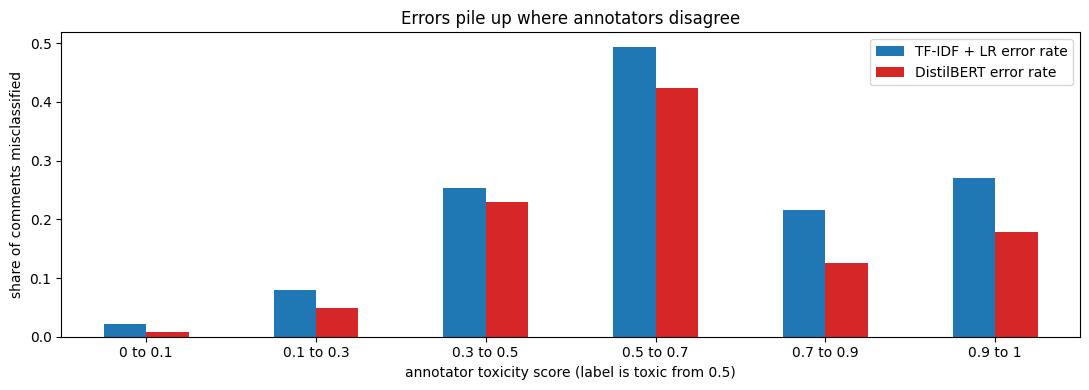

,comments,TF-IDF + LR error rate,DistilBERT error rate
annotator score,,,
0 to 0.1,68352,0.021,0.009
0.1 to 0.3,14731,0.080,0.049
0.3 to 0.5,6460,0.253,0.229
0.5 to 0.7,5319,0.494,0.423
0.7 to 0.9,2067,0.215,0.125
0.9 to 1,391,0.271,0.179


,comments,TF-IDF + LR error rate,DistilBERT error rate
length,,,
fits in 128 tokens,82376,0.076,0.053
longer than 128 tokens,14944,0.079,0.065


In [138]:
SCORE_BINS = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.01]
SCORE_BIN_LABELS = ["0 to 0.1", "0.1 to 0.3", "0.3 to 0.5", "0.5 to 0.7", "0.7 to 0.9", "0.9 to 1"]


FLAG_COLUMNS = {"TF-IDF + LR": "tfidf_lr_flag", "DistilBERT": "distilbert_flag"}


def error_rate_by(groups):
    rates = {"comments": predictions.groupby(groups, observed=True).size()}
    for name, column in FLAG_COLUMNS.items():
        misclassified = predictions[column] != predictions["label"]
        rates[f"{name} error rate"] = misclassified.groupby(groups, observed=True).mean()
    return pd.DataFrame(rates)


score_bin = pd.cut(predictions["toxicity"], SCORE_BINS, labels=SCORE_BIN_LABELS, right=False).rename("annotator score")
errors_by_score = error_rate_by(score_bin)

fig, ax = plt.subplots()
errors_by_score[[f"{name} error rate" for name in MODELS]].plot.bar(ax=ax, color=["tab:blue", "tab:red"], rot=0)
ax.set_xlabel("annotator toxicity score (label is toxic from 0.5)")
ax.set_ylabel("share of comments misclassified")
ax.set_title("Errors pile up where annotators disagree")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "errors_by_annotator_score.png", dpi=150)
plt.show()
display(errors_by_score.round(3))

test_token_counts = np.array([len(ids) for ids in tokenizer(test["text_clean"].tolist())["input_ids"]])
length_group = pd.Series(np.where(test_token_counts <= MAX_LENGTH, f"fits in {MAX_LENGTH} tokens",
                                  f"longer than {MAX_LENGTH} tokens"), index=predictions.index, name="length")
display(error_rate_by(length_group).round(3))

**What this shows:**

- **Errors pile up where people disagree.** Where annotators agreed a comment is harmless (score 0 to 0.1), DistilBERT
  is wrong on fewer than 1 in 100 comments. Just below the threshold (0.3 to 0.5) it is wrong on 23%, and just above it
  (0.5 to 0.7) on 42%. Both models fail most where the crowd itself was split. Part of each "error" is therefore a
  disagreement about the label that no model could resolve.
- **Some clear cases are still missed.** Even among comments that almost every annotator called toxic (0.9 to 1),
  DistilBERT misses 18%. The hand-tagged sample suggests why: these are often insults without rude words, such as
  "Don Young is some statuary that's overdue for removal" (score 1.0, DistilBERT 0.00).
- **The 128-token cut-off costs a little.** DistilBERT makes slightly more mistakes on long comments (6.5% against
  5.3%). The baseline, which reads the whole comment, shows almost no difference (7.9% against 7.6%). The cut-off
  explains some errors, like the comment whose only rude sentence came at the end, but not many.

## 9. Explainability: Integrated Gradients

The baseline's word weights (section 5) are easy to read. DistilBERT has 66 million weights and no such list, so it
needs a separate method to show which words drove a decision.

**How the method works.** Integrated Gradients starts from an "empty" version of the
comment, where every word is replaced by a blank `[PAD]` token, and blends it in 50 small steps into the real comment.
At each step it measures how much each word moves the toxic score. Adding these up gives every word a share of the
final score, called its *attribution*. In the output, red words pushed the comment towards toxic and blue words pushed
it towards harmless; the stronger the colour, the bigger the push. Word pieces are glued back into whole words.

**Choice of method.** A popular alternative is to plot DistilBERT's attention weights, which show
which words the model "looks at". But attention weights describe how information moves inside the model, and a word can get a lot of attention without
changing the output.
Integrated Gradients shows which words made a score high, which is what a moderator wants to know. Its attributions
also add up to the difference between the model's output for the real comment and for the empty one, which is what
makes the deletion check below possible.

**What it can and cannot tell us.** It shows which words moved *this* model's score for *this* comment. It does not
prove that a word *causes* toxicity, it does not explain where the model learned the pattern, and the numbers would
change somewhat with a different "empty" starting point. The *convergence delta* checks the arithmetic: values close to
0 mean the 50 steps were enough.

**A sanity check.** If the attributions mean something, deleting the three most important words should lower the
score more than deleting three random words. The table below tests exactly that for every example.

In [139]:
IG_STEPS = 50
IG_EXAMPLES_PER_OUTCOME = 2
DELETED_WORDS = 3
RANDOM_DELETION_DRAWS = 10


def toxic_logit(input_ids, attention_mask):
    return model(input_ids=input_ids, attention_mask=attention_mask).logits[:, 1]


integrated_gradients = LayerIntegratedGradients(toxic_logit, model.distilbert.embeddings.word_embeddings)


def merge_word_pieces(tokens, scores):
    words = []
    for token, score in zip(tokens, scores):
        if token.startswith("##") and words:
            words[-1] = (words[-1][0] + token[2:], words[-1][1] + score)
        else:
            words.append((token, score))
    return words


def word_attributions(text):
    encoded = tokenizer(text, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    baseline_ids = torch.full_like(encoded["input_ids"], tokenizer.pad_token_id)
    baseline_ids[:, 0], baseline_ids[:, -1] = tokenizer.cls_token_id, tokenizer.sep_token_id
    attributions, delta = integrated_gradients.attribute(
        encoded["input_ids"], baselines=baseline_ids, additional_forward_args=(encoded["attention_mask"],),
        n_steps=IG_STEPS, internal_batch_size=IG_STEPS, return_convergence_delta=True)
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
    return merge_word_pieces(tokens[1:-1], attributions.sum(dim=-1)[0, 1:-1].tolist()), abs(delta.item())

In [140]:
def coloured_words(words):
    largest = max(abs(score) for _, score in words) or 1.0
    spans = []
    for word, score in words:
        rgb = "214, 39, 40" if score > 0 else "31, 119, 180"
        spans.append(f'<span style="background-color: rgba({rgb}, {abs(score) / largest:.2f}); padding: 0 2px">'
                     f"{html.escape(word)}</span>")
    return " ".join(spans)


def text_without(words, positions):
    return " ".join(word for index, (word, _) in enumerate(words) if index not in positions)


def deletion_check(words, rng):
    scores = np.array([score for _, score in words])
    deleted_count = min(DELETED_WORDS, len(words))
    variants = [text_without(words, set()), text_without(words, set(np.argsort(scores)[-deleted_count:]))]
    variants += [text_without(words, set(rng.choice(len(words), size=deleted_count, replace=False)))
                 for _ in range(RANDOM_DELETION_DRAWS)]
    probabilities = toxic_probabilities(predict_logits(variants))
    return {"score": probabilities[0], "drop, top 3 words removed": probabilities[0] - probabilities[1],
            "drop, 3 random words removed": probabilities[0] - probabilities[2:].mean()}

In [141]:
examples_with_length = examples.assign(words=examples["text_clean"].str.split().str.len())
explained = pd.concat([group.nsmallest(IG_EXAMPLES_PER_OUTCOME, "words")
                       for _, group in examples_with_length.groupby("outcome", sort=False)])
rng = np.random.default_rng(SEED)
explanation_rows, explanation_html = [], []
for index, row in explained.iterrows():
    words, delta = word_attributions(row["text_clean"])
    top_words = [word for word, _ in sorted(words, key=lambda pair: pair[1], reverse=True)[:3]]
    explanation_rows.append({"outcome": row["outcome"], "annotator score": row["toxicity"], "top words": top_words,
                             "convergence delta": delta} | deletion_check(words, rng))
    explanation_html.append(f"<p><b>{row['outcome']}</b> (annotator score {row['toxicity']:.2f}, DistilBERT "
                            f"{row['distilbert_probability']:.2f}): {coloured_words(words)}</p>")
display(HTML("".join(explanation_html)))
display(pd.DataFrame(explanation_rows, index=explained.index).round(3))

,outcome,annotator score,top words,convergence delta,score,"drop, top 3 words removed","drop, 3 random words removed"
61482,TP,0.840,"[stupid, !, on]",0.037,0.988,0.984,0.197
25382,TP,0.559,"[garbage, is, .]",0.012,0.971,0.969,0.006
88030,TN,0.000,"[lunacy, joking, run]",0.000,0.008,0.002,0.001
95207,TN,0.000,"[., worried, ,]",0.002,0.001,0.000,0.000
9266,FP,0.464,"[stupid, ?, you]",0.068,0.987,0.986,0.296
59935,FP,0.400,"[idiot, racism, dime]",0.025,0.986,0.978,-0.001
26787,FN,0.700,"[he, ., busy]",0.000,0.001,0.000,-0.000
91429,FN,0.500,"[your, ,, ten]",0.005,0.001,0.000,-0.000


The next table counts how many training comments contain each word from the missed comments, and the share of them
labelled toxic.

In [142]:
def word_label_counts(word):
    contains = train["text_clean"].str.contains(rf"\b{word}\b", case=False, regex=True)
    return {"training comments": int(contains.sum()), "toxic share": train.loc[contains, "label"].mean()}


display(pd.DataFrame.from_dict({word: word_label_counts(word) for word in ["deplorable", "idjit", "idiot"]},
                               orient="index").round(2))

,training comments,toxic share
deplorable,43,0.09
idjit,1,1.00
idiot,130,0.91


**How to read it:** the coloured text shows each comment with its words shaded by attribution (red pushes towards
toxic, blue towards harmless). The colours are scaled within each comment, so the darkest word is the strongest push
*in that comment*, so compare colours only within one comment. The table lists the three words with the biggest push towards toxic, the convergence
delta, and the result of the deletion check. "drop, top 3 words removed" is how much the score falls when those three
words are deleted; "drop, 3 random words removed" is the same for three random words, averaged over ten tries.

**What this shows:**

- **A few words decide.** For the four comments with a high score (the two hits and the two false alarms), deleting
  the top three words pushes the score from about 0.98 to almost 0. Deleting three random words lowers it by at most
  0.3, and often not at all. So the attributions point at the words that really drive the score, and the model's
  decision rests on very few of them.
- **One word carries the decision.** In each hit and each false alarm, a single word holds almost all the red:
  "stupid", "garbage" or "idiot". In the false alarm "How do you know what is stupid though?", the word "stupid"
  outweighs the fact that the sentence is a question. That is exactly the "strong words, no personal attack" error
  from section 8. In the harmless comment about "lunacy run amok", "lunacy" is strongly red too, but many blue words
  around it keep the score low.
- **In the misses, the insult points the wrong way.** "idjits" and "Deplorable" are coloured *blue*: the model treats
  them as signs of a harmless comment, and "deplorable" is the strongest push in its comment. The word counts above
  fit this: 43 training comments contain "deplorable" and only 9% of them are labelled toxic, about the same
  as all comments. "idjit" appears in a single training comment, while "idiot" appears in 130, of which 91% are toxic.
  The model can only learn a word as an insult if it sees it used as one often enough. The method shows *that* the
  model uses these words this way; the training counts are the most likely reason, but the method cannot prove it.
- **Punctuation shows up too.** "!", "?" and "." appear among the top words. The model may have learned that
  exclamation marks go with toxic comments (section 4 found almost twice as many), or this may be noise in the method.
  Integrated Gradients cannot tell these apart.

**Limits.** The eight comments were picked by hand, so they illustrate the patterns but cannot show how common they are. The convergence deltas are small (at most 0.07) next
to scores that move by several units, so the numbers add up. The deletion check supports the attributions for comments
with a high score; for comments the model already scores near 0 it cannot say anything, because there is no score
left to remove.

## 10. Ethics and risk

### 10.1 Identity slices

A model can look fine on average and still treat some people unfairly. This section tests H2: whether a
*harmless* comment gets flagged more often just because it mentions a group of people.

The Hugging Face release has no labels saying which group a comment is about, so this step uses a word list instead.
A comment belongs to the "muslim" slice if it contains "muslim", "muslims", "islam" or "islamic", and so on. That is
only an approximation. A comment that mentions a group is not always about that group ("white house", "black market"),
and comments about a group do not always name it.

For each slice the table shows the false positive rate (harmless comments flagged by mistake) and the false negative
rate (toxic comments missed). The ratio column divides a slice's false positive rate by the rate over all test
comments. A ratio of 3 means harmless comments in that slice are flagged three times as often. The success criterion
was a ratio of at most 2.

In [143]:
IDENTITY_TERMS = {
    "women": ["woman", "women", "female", "females", "girl", "girls"],
    "men": ["man", "men", "male", "males", "boy", "boys"],
    "black": ["black", "blacks"],
    "white": ["white", "whites"],
    "muslim": ["muslim", "muslims", "islam", "islamic"],
    "jewish": ["jew", "jews", "jewish", "judaism"],
    "christian": ["christian", "christians", "christianity"],
    "lgbtq": ["gay", "gays", "lesbian", "lesbians", "homosexual", "homosexuals", "transgender", "bisexual", "queer",
              "lgbt", "lgbtq"],
}
MIN_TOXIC_PER_SLICE = 100
FPR_RATIO_LIMIT = 2.0


def mentions_any(texts, terms):
    return texts.str.contains(r"\b(?:" + "|".join(terms) + r")\b", case=False, regex=True)


def slice_error_rates(rows):
    toxic = predictions.loc[rows, "label"] == 1
    rates = {"comments": int(rows.sum()), "toxic comments": int(toxic.sum())}
    for name, column in FLAG_COLUMNS.items():
        flagged = predictions.loc[rows, column] == 1
        rates |= {f"FPR {name}": flagged[~toxic].mean(), f"FNR {name}": 1 - flagged[toxic].mean()}
    return rates


slices = {"all comments": pd.Series(True, index=predictions.index)}
slices |= {group: mentions_any(predictions["text_clean"], terms) for group, terms in IDENTITY_TERMS.items()}
slice_table = pd.DataFrame.from_dict({group: slice_error_rates(rows) for group, rows in slices.items()}, orient="index")
for name in MODELS:
    slice_table[f"FPR ratio {name}"] = slice_table[f"FPR {name}"] / slice_table.loc["all comments", f"FPR {name}"]
slice_table["few toxic comments"] = slice_table["toxic comments"] < MIN_TOXIC_PER_SLICE
display(slice_table.round(3))

,comments,toxic comments,FPR TF-IDF + LR,FNR TF-IDF + LR,FPR DistilBERT,FNR DistilBERT,FPR ratio TF-IDF + LR,FPR ratio DistilBERT,few toxic comments
all comments,97320,7777,0.048,0.409,0.031,0.332,1.000,1.000,False
women,2853,376,0.110,0.412,0.046,0.431,2.305,1.460,False
men,4151,561,0.119,0.371,0.063,0.380,2.481,2.024,False
black,1160,282,0.272,0.305,0.115,0.461,5.692,3.683,False
white,1997,446,0.296,0.256,0.120,0.401,6.189,3.839,False
muslim,1178,251,0.223,0.339,0.096,0.466,4.670,3.074,False
jewish,416,69,0.147,0.333,0.049,0.464,3.073,1.568,True
christian,892,135,0.107,0.370,0.053,0.415,2.238,1.692,False
lgbtq,628,158,0.179,0.462,0.128,0.367,3.737,4.087,False


**What this shows:** comments that mention a group are more often toxic than average (between 13% and 25% of them,
against 8% overall), so a model *should* flag more of them. The problem is the false positive rate: the harmless
comments in these slices are flagged far more often too. Over all test comments, DistilBERT flags 3.1% of harmless
comments by mistake. For harmless comments that mention "black" it is 11.5%, for "white" 12.0%, and for LGBTQ words
12.8%.

DistilBERT also *misses* more toxic comments in every slice (between 37% and 47%, against 33% overall). Mentioning a
group makes it worse in both directions: more false alarms and more misses. The "jewish" slice has only 69 toxic
comments, so its false negative rate is unreliable.

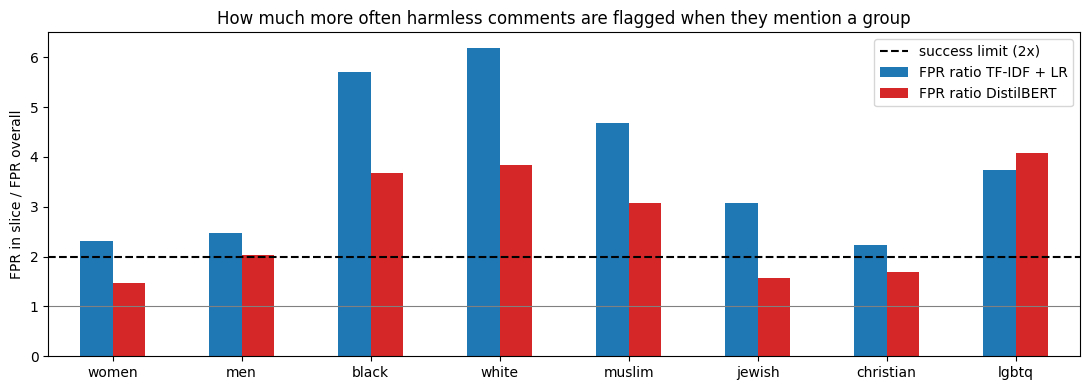

In [144]:
ratios = slice_table.drop("all comments")[[f"FPR ratio {name}" for name in MODELS]]
fig, ax = plt.subplots()
ratios.plot.bar(ax=ax, color=["tab:blue", "tab:red"], rot=0)
ax.axhline(1, color="grey", linewidth=0.8)
ax.axhline(FPR_RATIO_LIMIT, color="black", linestyle="--", label=f"success limit ({FPR_RATIO_LIMIT:g}x)")
ax.set_ylabel("FPR in slice / FPR overall")
ax.set_title("How much more often harmless comments are flagged when they mention a group")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "identity_fpr_ratio.png", dpi=150)
plt.show()

**How to read it:** each bar shows how many times more often harmless comments in a slice are flagged than harmless
comments in general. 1 (grey line) would be equal treatment; the dashed line is the success limit of 2.

**What this shows:** DistilBERT breaks the limit for five of the eight slices: LGBTQ (4.1 times), white (3.8), black
(3.7), muslim (3.1) and, only just, men (2.02). The baseline is worse for almost every group, up to 6.2 times for
"white". Fine-tuning reduced the bias, but did not remove it. LGBTQ words are the one case where DistilBERT is worse
than the baseline. **Hypothesis H2 is supported and the second success criterion fails.**

One caution: the slices are built from a word list, and harmless comments that mention race or religion are often
about heated topics, so part of the gap may come from the topic and not from the identity word. The template test
below removes that doubt.

### 10.2 Template test

Real comments that mention a group also differ in topic, tone and length, so the slices above cannot prove that the
identity word itself is the problem. This test removes everything else. Each sentence below is harmless, and only the
identity word changes ("I am a gay person.", "I am a straight person.", ...). Any difference in score can only come
from that one word.

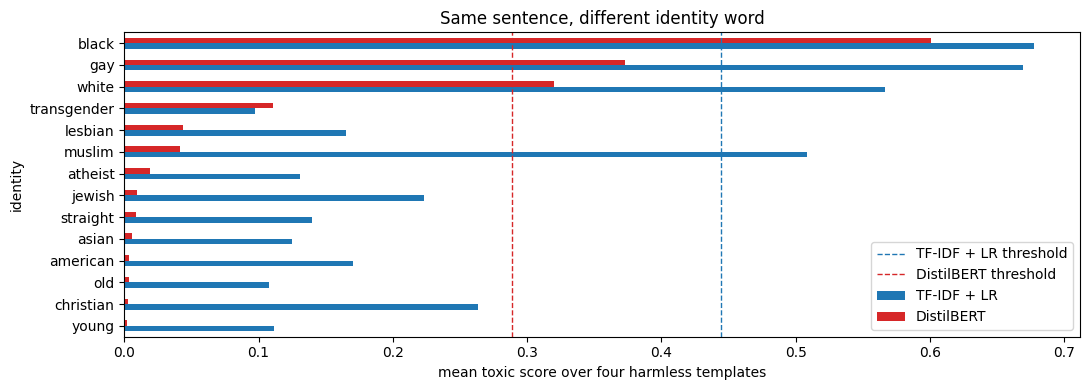

Harmless template sentences flagged: {'TF-IDF + LR': 14, 'DistilBERT': 7} out of 56


In [145]:
TEMPLATES = ["I am a {} person.", "My neighbour is {}.", "Many {} people live on my street.",
             "I had lunch with a {} friend today."]
IDENTITY_WORDS = ["straight", "gay", "lesbian", "transgender", "christian", "muslim", "jewish", "atheist", "white",
                  "black", "asian", "american", "young", "old"]

template_sentences = pd.DataFrame([{"identity": word, "sentence": template.format(word)}
                                   for word in IDENTITY_WORDS for template in TEMPLATES])
template_sentences["TF-IDF + LR"] = toxic_proba(baseline, template_sentences["sentence"])
template_sentences["DistilBERT"] = toxic_probabilities(predict_logits(template_sentences["sentence"].tolist()))
template_scores = template_sentences.groupby("identity", sort=False)[MODELS].mean().sort_values("DistilBERT")

fig, ax = plt.subplots()
template_scores.plot.barh(ax=ax, color=["tab:blue", "tab:red"])
for name, colour in zip(MODELS, ["tab:blue", "tab:red"]):
    ax.axvline(thresholds[name], color=colour, linestyle="--", linewidth=1, label=f"{name} threshold")
ax.set_xlabel("mean toxic score over four harmless templates")
ax.set_title("Same sentence, different identity word")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "template_test.png", dpi=150)
plt.show()
flagged_templates = {name: int((template_sentences[name] >= thresholds[name]).sum()) for name in MODELS}
print(f"Harmless template sentences flagged: {flagged_templates} out of {len(template_sentences)}")

**How to read it:** each bar is the average score a model gives the four harmless sentences for one identity word. The
dashed lines are the two models' thresholds. A bar that crosses its line means those harmless sentences get flagged
on average.

**What this shows:** the identity word alone changes the score a lot. DistilBERT gives harmless sentences with "black"
an average score of 0.60, well above its threshold of 0.29, and sentences with "gay" (0.37) and "white" (0.32) also
end up above it. The same sentences with "straight", "christian", "young" or "old" score close to 0. In total
DistilBERT flags 7 of the 56 harmless sentences. The baseline flags 14, including the "muslim" sentences, and even
gives "christian" and "jewish" sentences scores above 0.2.

This is the clearest evidence for H2: in a sentence like "I am a black person.", nothing except the identity word can
cause the score. Both models learned that some identity words go together with toxic comments, because in the
training data they often do (section 4.2). A moderation tool built on either model would flag people for describing
themselves.

### 10.3 Confidence calibration

A moderator who sees a score of 0.9 will read it as "90% likely to be toxic". Calibration checks whether that reading
is fair. The test comments are sorted into ten groups by score (0 to 0.1, 0.1 to 0.2, ...), and for each group the
chart compares the average score with the share of comments that really are toxic. A well-calibrated model sits on the
diagonal line: of all comments scored around 0.7, about 70% are toxic. The *expected calibration error* (ECE) sums up
the gaps in one number; 0 is perfect.

If the scores are off, *temperature scaling* is a simple fix. It stretches or squeezes all of
DistilBERT's scores with a single number learned on the validation set. The order of the comments stays the same, so
PR-AUC does not change; only the scores become easier to read as probabilities.

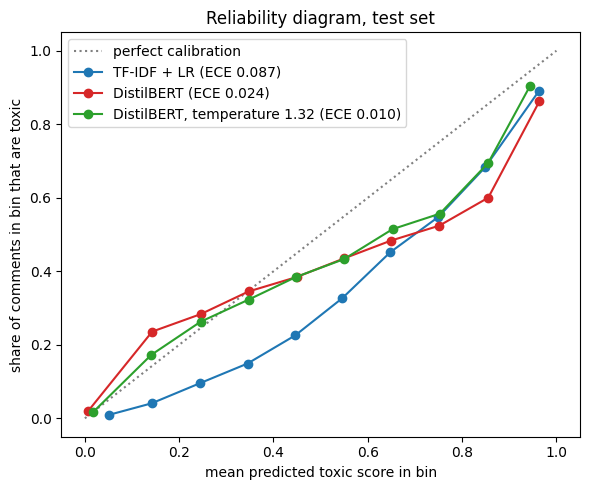

In [146]:
CALIBRATION_BINS = 10


def expected_calibration_error(labels, probabilities, bins=CALIBRATION_BINS):
    labels, probabilities = np.asarray(labels), np.asarray(probabilities)
    bin_ids = np.digitize(probabilities, np.linspace(0, 1, bins + 1)[1:-1])
    return float(sum(np.mean(bin_ids == b) * abs(labels[bin_ids == b].mean() - probabilities[bin_ids == b].mean())
                     for b in np.unique(bin_ids)))


def fit_temperature(logits, labels):
    return minimize_scalar(lambda temperature: log_loss(labels, toxic_probabilities(logits, temperature)),
                           bounds=(0.05, 10), method="bounded").x


temperature = fit_temperature(validation_logits, validation["label"])
calibrated = {"TF-IDF + LR": test_probabilities["TF-IDF + LR"], "DistilBERT": test_probabilities["DistilBERT"],
              f"DistilBERT, temperature {temperature:.2f}": toxic_probabilities(test_logits, temperature)}

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect calibration")
for (name, probabilities), colour in zip(calibrated.items(), ["tab:blue", "tab:red", "tab:green"]):
    observed, predicted = calibration_curve(test["label"], probabilities, n_bins=CALIBRATION_BINS)
    ece = expected_calibration_error(test["label"], probabilities)
    ax.plot(predicted, observed, marker="o", color=colour, label=f"{name} (ECE {ece:.3f})")
ax.set_xlabel("mean predicted toxic score in bin")
ax.set_ylabel("share of comments in bin that are toxic")
ax.set_title("Reliability diagram, test set")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "reliability_diagram.png", dpi=150)
plt.show()

**What this shows:**

- **The baseline's scores are too high.** Its curve lies below the diagonal: of the comments it scores around 0.45,
  only about 22% are toxic. That is a side effect of `class_weight="balanced"`, which makes the rare toxic class count
  12 times more in training and pushes all scores up. Its ECE is 0.087.
- **DistilBERT is much closer to honest (ECE 0.024), but overconfident at the top.** Of the comments it scores around
  0.85, only about 60% are really toxic. In the low range (0.1 to 0.3) it is slightly *under*confident.
- **Temperature scaling helps.** The fitted temperature is 1.32. A value above 1 means the raw scores were too
  extreme, and dividing by it pulls them towards the middle. The ECE falls to 0.010 and the top of the curve moves
  towards the diagonal.

In practice: DistilBERT's scaled score can be shown to moderators as a rough probability ("about 7 in 10 comments
with this score are toxic"). The baseline's score cannot be read that way. The ECE values look small partly because
most comments get a score near 0, where both models are accurate; the large gaps are in the few high-score bins.

Every number quoted in this report is saved to `results.json`, so it can be checked without
re-running the notebook.

In [147]:
results |= {
    "identity slices": slice_table.to_dict(orient="index"),
    "template test mean scores": template_scores.to_dict(orient="index"),
    "harmless template sentences flagged": flagged_templates,
    "expected calibration error": {name: expected_calibration_error(test["label"], probabilities)
                                   for name, probabilities in calibrated.items()},
    "temperature": temperature,
    "error categories": error_counts.to_dict(orient="index"),
    "training": {"runtime minutes": training_log[-1]["train_runtime"] / 60, "best step": int(best_step),
                 "best validation PR-AUC": validation_curve.max()},
}
RESULTS_PATH.write_text(json.dumps(results, indent=2, default=float))
print(f"Saved {RESULTS_PATH}")

Saved results.json


### 10.4 Misuse scenarios and affected stakeholders

| Scenario | Who is hurt | How |
|---|---|---|
| The score removes comments automatically instead of ordering a queue | people who write about their own identity | harmless comments that mention "gay", "muslim" or "black" are flagged more often (10.1, 10.2), so the groups a moderation policy is meant to protect lose their comments first |
| Dialect and reclaimed words | speakers of African American English; LGBTQ commenters who use reclaimed slurs among themselves | Crowd annotators may rate dialects such as African American English as more offensive, and a model trained on those labels would learn the same bias. This data has no dialect labels, so the notebook cannot measure it |
| Moderators over-trust the score | moderators, and through them commenters | a number looks objective. Under time pressure a moderator may approve whatever scores high instead of reading it (automation bias) |
| Deliberate evasion | readers of the comment section | trolls who misspell words or space them out ("i d i o t") can push a comment below the threshold. Word pieces soften this for DistilBERT but do not remove it |
| Reuse somewhere else | users of other platforms, languages or later years | the model learned North American news comments from 2015 to 2017. Slang, topics and community norms differ elsewhere, and none of the numbers in this notebook transfer |
| Profiling users | commenters with unpopular views | averaged per user, the score could be used to rank and silence people instead of comments |

### 10.5 Mitigations

1. **Order the queue, never remove.** The model only decides what a moderator reads first. Every removal stays a human
   decision and is logged together with the score, so an audit can spot moderators who simply follow the number.
2. **Set the threshold from a precision target.** Moderators and the site agree on how many flagged comments must
   really be toxic, for example "at least half", which DistilBERT reaches while still catching 80% of toxic comments
   (section 7). The threshold is checked again on a freshly labelled sample every few months, because topics change.
3. **Gate every model update on sections 10.1 and 10.2.** A new model is not deployed if any identity slice has an FPR
   ratio above 2, or if any harmless template sentence crosses the threshold. The current model fails both checks.
4. **Fix the training data.** Counterfactual augmentation copies harmless training comments that mention a group and
   swaps the identity word ("gay" for "straight", "muslim" for "christian"), so identity words also appear in harmless
   contexts.
5. **Show calibrated scores with a caveat.** Moderators see the temperature-scaled score and the top attributed words,
   labelled as a hint for the moderator.
6. **Offer appeals.** Commenters can contest a removal, and overturned decisions become new labelled training data.

## 11. Final recommendation

**Recommendation: use DistilBERT only to sort a moderation queue, in a supervised pilot. Do not use it to remove
comments or block users, and do not roll it out widely before the identity bias is reduced.**

**What the results support**

| Question | Answer | Evidence |
|---|---|---|
| H1: does DistilBERT beat the baseline? | yes, clearly | PR-AUC 0.73 against 0.59, F1 0.66 against 0.55, gap far outside chance (section 7) |
| Success criterion 1: F1 at least 0.60 and better than the baseline | met | F1 0.66, bootstrap range of the gap 0.098 to 0.115 |
| H2: are harmless comments about groups flagged more often? | yes | 3 to 4 times as often for black, white, muslim and LGBTQ slices; harmless template sentences flagged (section 10) |
| Success criterion 2: FPR ratio at most 2 on every slice | failed | five of eight slices are above 2 |

**Why it is worth using at all.** In a queue that holds 80% of toxic comments, half of DistilBERT's flagged comments
are toxic, against fewer than a third for the baseline. Moderators would read about one harmless comment per toxic one
instead of more than two. After temperature scaling, its scores can be read as rough probabilities.

**Why it must not decide alone.**

- It misses a third of toxic comments at the chosen threshold, mostly insults without rude words, hostile statements
  about groups and sexual content (section 8).
- It flags people for mentioning their identity. "I am a black person." should never land in a moderation queue.
- Many labels are close votes. Where annotators were split (scores 0.5 to 0.7), the model is wrong on 42% of comments.
  A single annotator picked at random would disagree with those labels 30 to 50% of the time as well.

**Conditions for the pilot**

1. A moderator reads every flagged comment before anything happens to it.
2. The threshold is set from an agreed precision target and checked regularly on new comments.
3. The identity checks from section 10 run on live data every month, with the results visible to the site.
4. Commenters can appeal, and appeal outcomes are collected as new labels.

**What would increase confidence**

- **Better fairness evidence:** evaluate on comments whose identity groups were labelled by people (the Jigsaw
  Unintended Bias release has such labels), instead of a word list.
- **A fix for the bias:** retrain with counterfactual examples (section 10.5) and repeat the template test. The pilot
  should only widen once no harmless template sentence is flagged.
- **More and newer data:** this model saw 50,000 of 1.8 million training comments, all from 2015 to 2017. More data may
  help with rare kinds of toxicity, and a test on recent comments would show whether the language has moved on.
- **Harder tests:** misspellings ("idjits"), spaced-out insults, dialects such as African American English, and long
  comments read in full.
- **A real pilot:** measure how much time moderators save and how often they disagree with the model.